# Retinal disease classification on FIVES with classical machine learning

This notebook **loads the saved outputs** of `scripts/01_...09_` (tables, figures, predictions, model) and re-displays the key results. It does not retrain anything
except one live demonstration of preprocessing and one inference demo with `src.predict.predict_image`.
Run `python scripts/run_all.py` first to regenerate the outputs.

In [1]:
import sys, io, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from PIL import Image as PILImage
from IPython.display import Image, Markdown, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.py").exists())
sys.path.insert(0, str(ROOT))
import config
T, FIG = config.TABLES_DIR, config.FIGURES_DIR
pd.set_option("display.width", 200, "display.max_columns", 40, "display.float_format", "{:.3f}".format)

def fig(name, width=1300):
    """Display a saved figure (downscaled to keep the notebook small)."""
    im = PILImage.open(FIG / name).convert("RGB")
    if im.width > width:
        im = im.resize((width, round(im.height * width / im.width)), PILImage.LANCZOS)
    buf = io.BytesIO(); im.save(buf, "PNG", optimize=True)
    display(Image(data=buf.getvalue(), format="png"))

def table(name, **kw):
    display(pd.read_csv(T / name, **kw))

def md_file(path, drop_title=True):
    s = (ROOT / path).read_text()
    if drop_title: s = "\n".join(s.splitlines()[1:])
    display(Markdown(s))
print("project root:", ROOT)

project root: /home/ghotra/Projects/Minor/fives-project


## 1. Problem

Classify a colour fundus photograph into one of four classes: **Normal, AMD, Diabetic Retinopathy (DR), Glaucoma**, using classical machine learning on extracted features
(not an end-to-end CNN). Goals: EDA, careful preprocessing without leakage, at least three models compared fairly, tuning/ensembling, and a deployable best model that takes one image.
Because the data are small (800 images) and chance is 25%, the main scientific point is *how far the reported numbers can be trusted*.

## 2. Dataset

**FIVES** (Figshare, DOI 10.6084/m9.figshare.19688169; Jin K. et al., Sci Data 9, 475 (2022)): 800 fundus images at 2048 x 2048, 200 per class, official split 600 train / 200 test,
with vessel masks (used only for sanity checks). The class is the filename suffix letter. It is not a Kaggle dataset.

In [2]:
man = pd.read_csv(config.DATA_DIR / "manifest.csv")
print("images after cleaning:", len(man))
display(pd.crosstab(man.label_name, man.official_split).reindex(config.CLASS_NAMES))
print("Cleaning log (every removed image):")
table("cleaning_log.csv")

images after cleaning: 793


official_split,test,train
label_name,,
Normal,50,150
AMD,49,144
Diabetic Retinopathy,50,150
Glaucoma,50,150


Cleaning log (every removed image):


,split,file,reason,detail
0,train,132_A.png,exact_duplicate,md5=35dc54e982bf1fe229d2221bbeaeae34; kept tra...
1,train,97_A.png,exact_duplicate,md5=43b47604628b30acdc20761d21b72daf; kept tra...
2,train,134_A.png,exact_duplicate,md5=56115f6921063b22a53e6b9f6cf96fd1; kept tra...
3,train,118_A.png,exact_duplicate,md5=942ff7e5a25cff7e5adb834660a84177; kept tra...
4,train,121_A.png,exact_duplicate,md5=a58a62ab138d0543e3255aea7cf0cf06; kept tra...
5,test,48_A.png,exact_duplicate,md5=bcccf20f77be8c137506c321cc8b9915; kept tes...
6,train,80_A.png,near_duplicate_crosses_split,"pair with test/21_A.png (phash 6, corr 0.9937)..."


In [3]:
md_file('results/audit_summary.md')


Root: `/home/ghotra/Downloads/dataset`  
Originals: 800, masks: 800, other files: 2

## Findings

- Layout: originals in `test/Original`, `train/Original`; masks (vessel segmentation, not class labels) in `test/Ground truth`, `train/Ground truth`; splits found: ['test', 'train'].
- Label parsing: all 800 original images match `<id>_<A|D|G|N>`.
- Numeric ids restart in each split (200 ids appear in both train and test, e.g. train/1_A and test/1_A are different images). Files must be keyed by split+filename, never id alone.
- Class counts per split:


| label                |   test |   train |   total |
|:---------------------|-------:|--------:|--------:|
| AMD                  |     50 |     150 |     200 |
| Diabetic Retinopathy |     50 |     150 |     200 |
| Glaucoma             |     50 |     150 |     200 |
| Normal               |     50 |     150 |     200 |

Classes are perfectly balanced within each split.
- Integrity: every original and mask opened and decoded without error.
- All originals are 2048x2048 RGB/PNG.
- Masks: all 800 originals have a same-name mask in the same split.
- Duplicates: 6 exact md5 groups; phash gave 2922 candidates (unreliable alone: it collides across classes), of which 9 are confirmed by pixel correlation >= 0.99; 1 confirmed pairs cross train/test.
- Quality (whole image, black background included), mean per class:


| label                |   brightness |   contrast |   blur_lapvar |   saturation |
|:---------------------|-------------:|-----------:|--------------:|-------------:|
| AMD                  |        65.72 |      40.52 |          9.29 |       209.51 |
| Diabetic Retinopathy |        52.94 |      33.58 |          8.14 |       216.57 |
| Glaucoma             |        37    |      26.24 |          7.56 |       195.89 |
| Normal               |        46.92 |      30.28 |          5.15 |       194.69 |

If these differ strongly by class, acquisition-style differences could leak into colour/intensity features (a shortcut to flag in EDA).
- Max/min ratio of class means: brightness=1.78, contrast=1.54, blur_lapvar=1.8, saturation=1.11

## Issues

- 2 non-image file(s) present: ['Quality Assessment.xlsx', 'Thumbs.db']
- 6 exact-duplicate group(s) by md5 (labels: ['AMD']; 0 span splits): de-duplicate before CV or folds leak
- 3 further near-duplicate pair(s) that are not byte-identical
- 1 confirmed near-duplicate pair(s) across train/test (leakage)

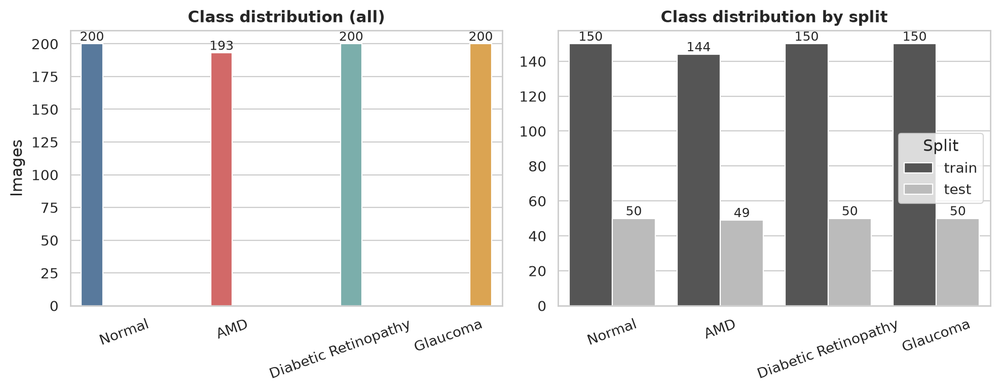

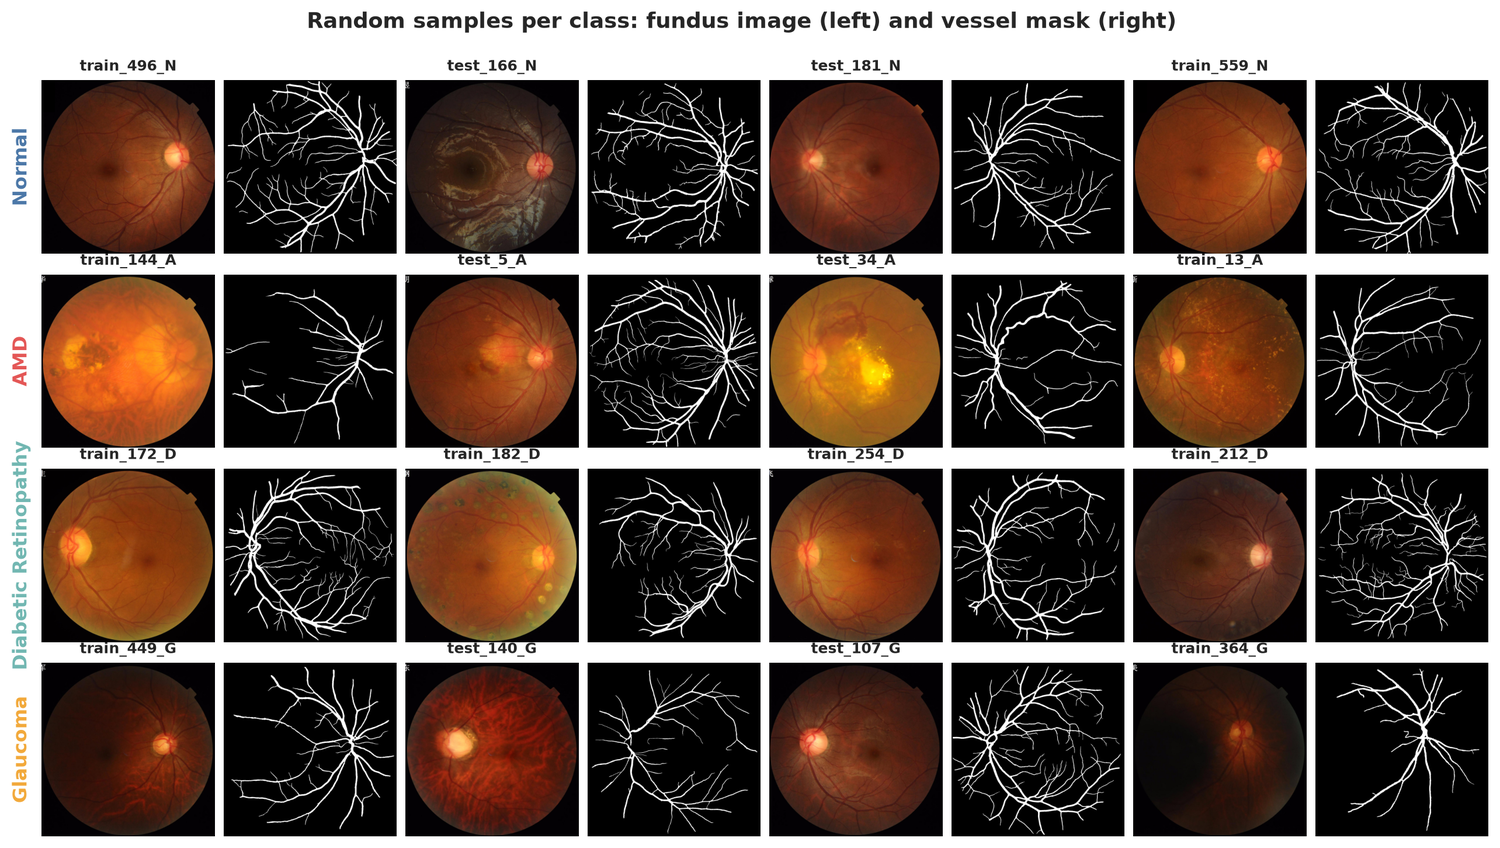

In [4]:
fig('eda_01_class_distribution.png', 1000); fig('eda_02_sample_grid.png', 1500)

## 3. Exploratory data analysis

In [5]:
md_file('results/eda_insights.md')


- **Class balance:** 793 images; train {'Normal': 150, 'AMD': 144, 'Diabetic Retinopathy': 150, 'Glaucoma': 150}, test {'Normal': 50, 'AMD': 49, 'Diabetic Retinopathy': 50, 'Glaucoma': 50}. Imbalance ratio (max/min) is 1.04 in train and 1.02 in test (only AMD lost images to de-duplication), so accuracy is a fair metric but macro-F1 will be reported too.
- **Uniform geometry:** 1 distinct resolution(s) (2048x2048), all RGB PNG; file size 0.4-3.3 MB. No resizing is needed to unify inputs, only to reduce cost.
- **Brightness and contrast differ strongly by class** (Kruskal-Wallis p<1e-10, e2=0.37 and p<1e-10, e2=0.33). Mean gray: Normal 46.9, AMD 65.6, Diabetic Retinopathy 52.9, Glaucoma 37.0; std gray: Normal 30.3, AMD 40.4, Diabetic Retinopathy 33.6, Glaucoma 26.2. AMD images are ~1.8x brighter than Glaucoma.
- **Sharpness differs by class, driven by the Normal training images** (p<1e-10, e2=0.27). Laplacian variance: Normal 5.15, AMD 9.28, Diabetic Retinopathy 8.14, Glaucoma 7.56. Normal is 4.09 in train but 8.36 in test, while the other classes agree across splits (train/test: AMD 9.28/9.30, Diabetic Retinopathy 8.17/8.05, Glaucoma 7.61/7.42) - the train Normal images (ids 451-600) look like a different acquisition batch.
- **Overlay glyph in the image corner is a source marker:** bright pixels in the top-left 120px corner (outside the FOV) appear in Normal 3%/86%, AMD 98%/96%, Diabetic Retinopathy 80%/82%, Glaucoma 85%/86% of images (train/test). Normal is the outlier: 3% of train but 86% of test Normal images carry it, so a model can learn 'no glyph (and soft focus) = Normal' on train and fail on test. Mask or crop the corner (use a circular FOV mask) before feature extraction, and expect a Normal train/test shift to show up as Normal recall errors.
- **Black border differs by class:** FOV fraction of the frame Normal 0.772, AMD 0.757, Diabetic Retinopathy 0.757, Glaucoma 0.747 (p<1e-10, e2=0.40). Whole-image brightness/contrast/blur therefore mix scene content with border size; mask the FOV before computing features.
- **Shortcut-learning risk is real:** a random forest on only the 4 quality numbers (brightness, contrast, blur, FOV fraction) reaches 66.3% +/- 3.2% 5-fold CV accuracy on train (chance 25%); mean R/G/B alone reaches 50.5% +/- 2.5%. Global intensity features must be normalised (e.g. per-image colour/illumination normalisation) and results interpreted with this baseline in mind.
- **Vessel density** (vessel px / FOV px) by class: Normal 0.115, AMD 0.097, Diabetic Retinopathy 0.090, Glaucoma 0.086; ordered Glaucoma < Diabetic Retinopathy < AMD < Normal (Kruskal-Wallis p<1e-10, e2=0.26). Masks are binary (2 gray levels), but they exist only for dataset images: using density as a feature in the app would need a vessel segmenter.
- **Colour balance differs:** mean channel values inside the FOV (R/G/B) differ across classes (R p<1e-10, e2=0.40; G e2=0.35; B e2=0.14); green share of total intensity: Normal 0.269, AMD 0.286, Diabetic Retinopathy 0.279, Glaucoma 0.264. In the histograms blue is concentrated at low values, green sits mid-low and red is broad and highest; AMD shows a red saturation spike at 255.
- **Metric structure:** brightness and contrast are strongly coupled (Spearman Normal 0.91, AMD 0.98, Diabetic Retinopathy 0.96, Glaucoma 0.90); all off-diagonal |rho| range 0.26-0.98 across classes, so correlated features are expected and regularisation/feature selection inside the CV pipeline is warranted. Train vs test distributions of the quality metrics differ (Mann-Whitney p: blur_score 2.4e-05, brightness 0.86, contrast 0.2).

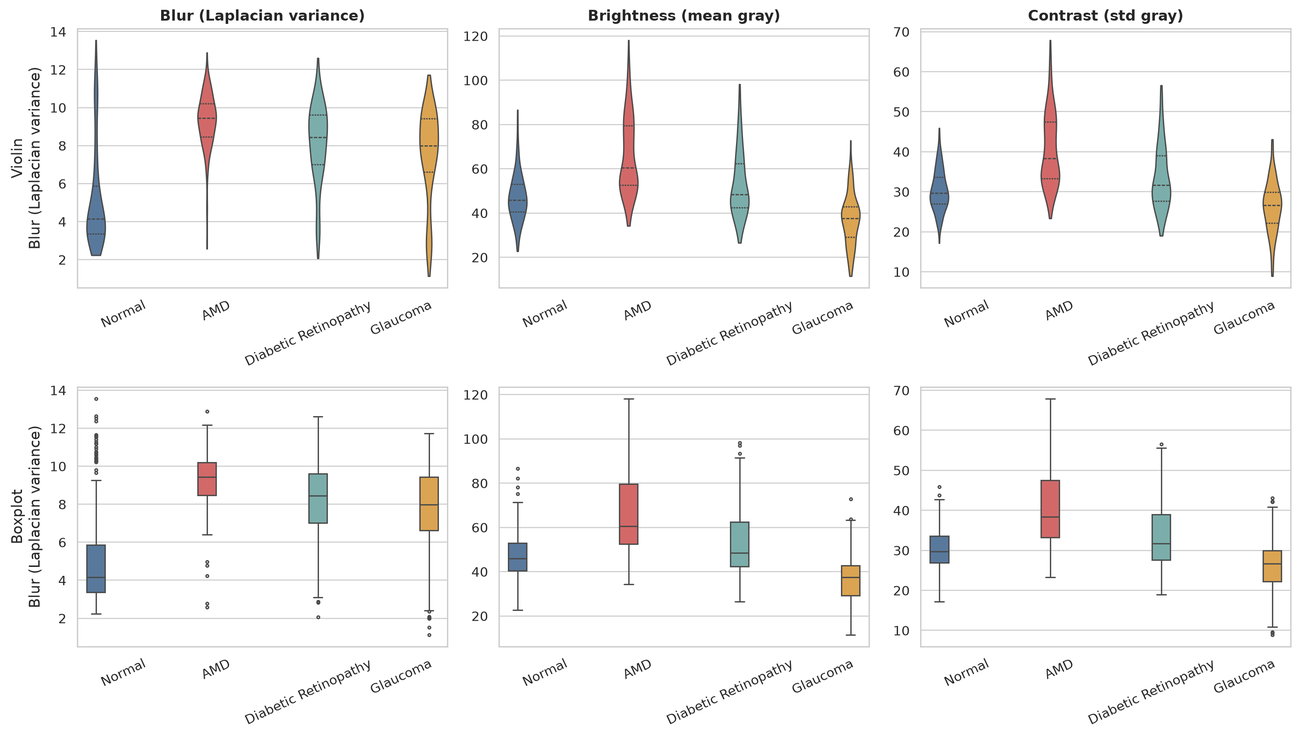

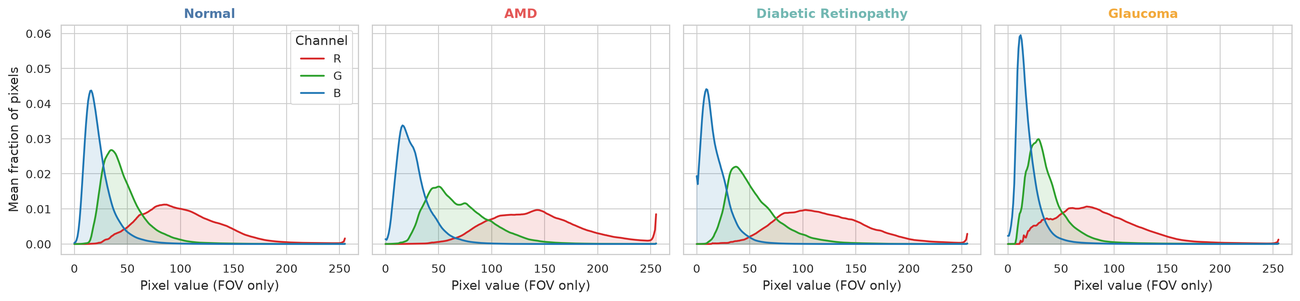

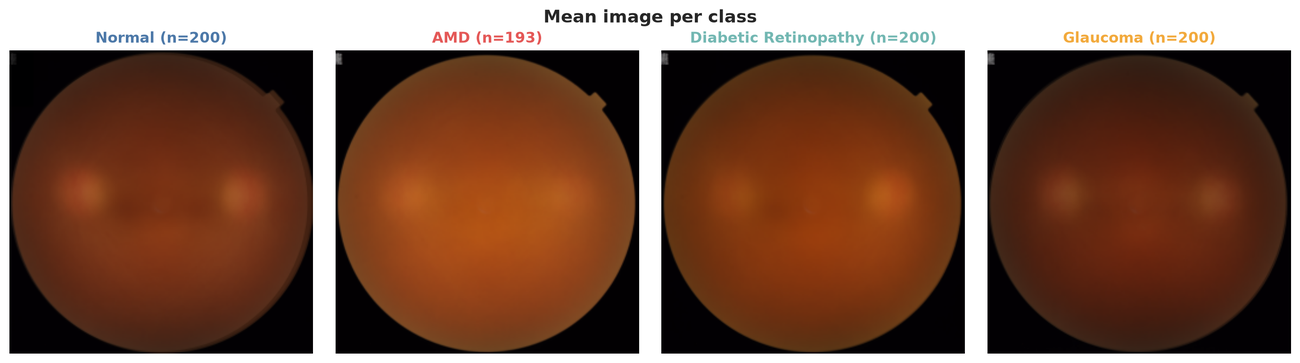

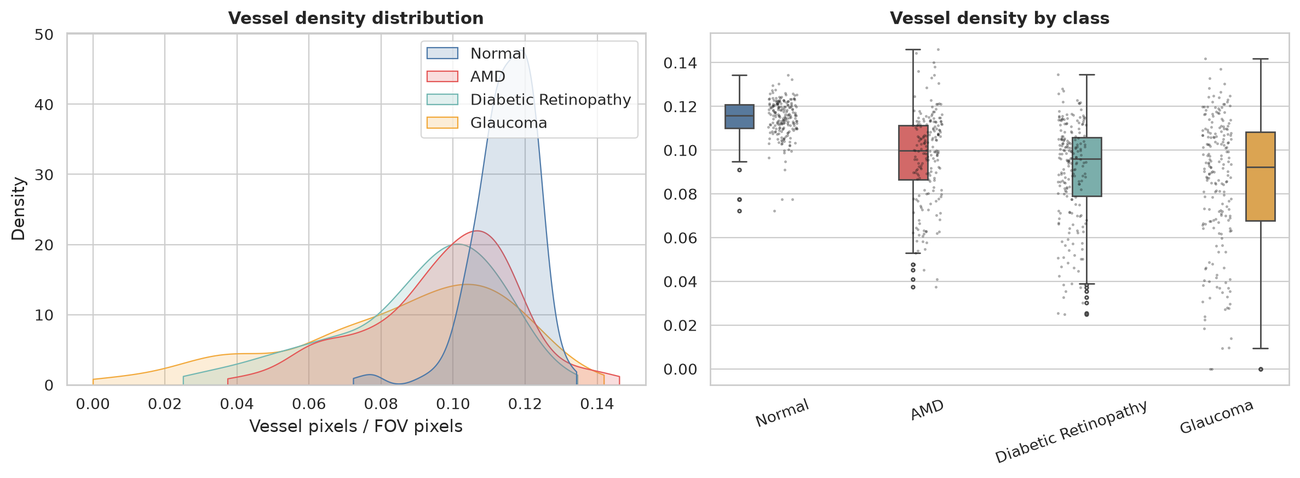

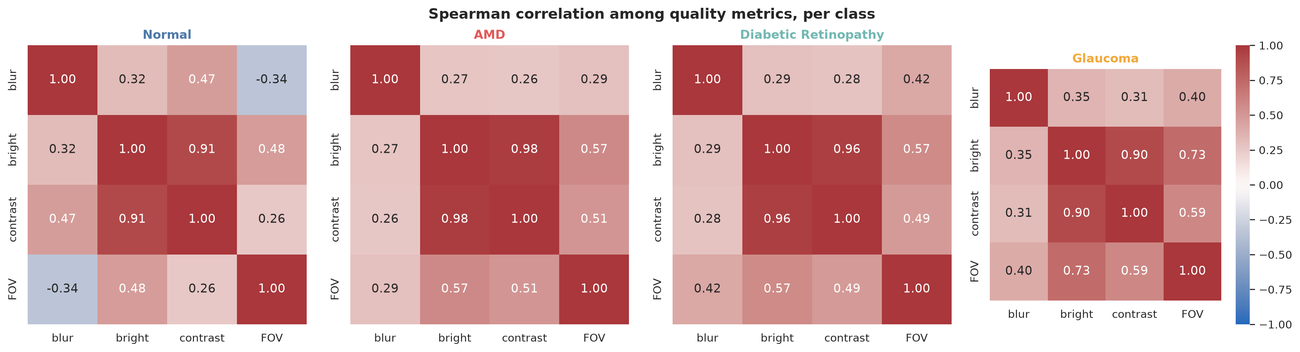

In [6]:
for f in ['eda_04_quality_by_class.png', 'eda_05_rgb_histograms.png', 'eda_06_mean_image.png', 'eda_07_vessel_density.png', 'eda_08_quality_correlation.png']: fig(f)

## 4. Preprocessing and features

Per image: resize to 512, detect the field of view (FOV), crop to it, apply a circular FOV mask (this also removes the corner glyph that marks the image source), CLAHE on the green channel;
the *normalised* variant additionally divides the green channel by a large-scale blur and standardises each channel inside the FOV. Then 116 handcrafted features (colour 81, texture 14, vessel 11, bright-region 10);
ResNet50 embeddings are computed separately. The live demo below runs the real preprocessing on one test image per class.

In [7]:
from src import features as F
te = man[man.official_split == "test"]
fig_, ax = plt.subplots(4, 4, figsize=(14, 14))
for r, c in enumerate(range(4)):
    row = te[te.label_id == c].iloc[0]
    path = config.DATASET_PATH / row.image_path
    p = F.preprocess(path); n = F.normalise(p)
    raw = F.as_rgb(path)
    ax[r, 0].imshow(PILImage.fromarray(raw).resize((384, 384))); ax[r, 1].imshow(p["rgb"]); ax[r, 2].imshow(p["green"], cmap="gray"); ax[r, 3].imshow(n["rgb"])
    ax[r, 0].set_ylabel(row.label_name, fontsize=12)
    for a, t in zip(ax[r], ["raw (corner glyph visible)" if r == 0 else "raw", "FOV crop + circular mask", "CLAHE green", "normalised"]):
        a.set_title(t, fontsize=9); a.set_xticks([]); a.set_yticks([])
fig_.tight_layout(); plt.show()

In [8]:
from src.preprocess import build_pipeline
print(build_pipeline())
rank = pd.read_csv(T / "feat_anova_ranking.csv")
print("\nfeatures per group and mean ANOVA F:")
display(rank.groupby("group").agg(n=("feature", "count"), mean_F=("F", "mean")))
print("top 12 features by ANOVA F (train):"); display(rank.head(12)[["feature", "group", "F"]])
print("vessel features vs ground-truth vessel density (train):"); table("feat_vessel_sanity.csv")

Pipeline(steps=[('impute', SimpleImputer(strategy='median')),
                ('scale', RobustScaler()), ('variance', VarianceThreshold()),
                ('corr', CorrelationFilter()), ('select', SelectKBest(k=30))])

features per group and mean ANOVA F:


,n,mean_F
group,,
color,81,63.777
disc,10,21.209
tex,14,57.399
vessel,11,30.017


top 12 features by ANOVA F (train):


,feature,group,F
0,color_LAB_b_mean,color,137.429
1,color_LAB_b_p50,color,133.371
2,color_LAB_b_p75,color,133.170
3,color_LAB_b_p25,color,124.931
4,color_LAB_b_p95,color,123.835
5,color_RGB_R_mean,color,122.024
6,color_HSV_V_mean,color,122.014
7,color_RGB_R_p75,color,120.978
8,color_HSV_V_p75,color,120.971
9,color_RGB_R_p50,color,119.690


vessel features vs ground-truth vessel density (train):


,feature,pearson_r,spearman_rho
0,vessel_density,0.562,0.566
1,vessel_skeleton_density,0.410,0.461
2,vessel_frangi_mean,0.379,0.392


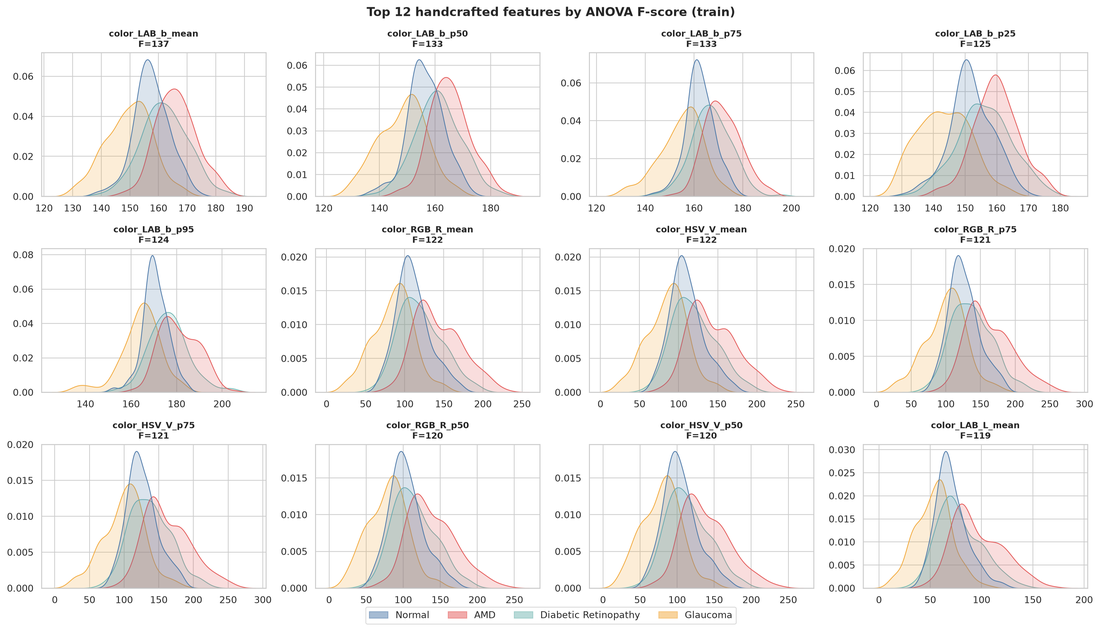

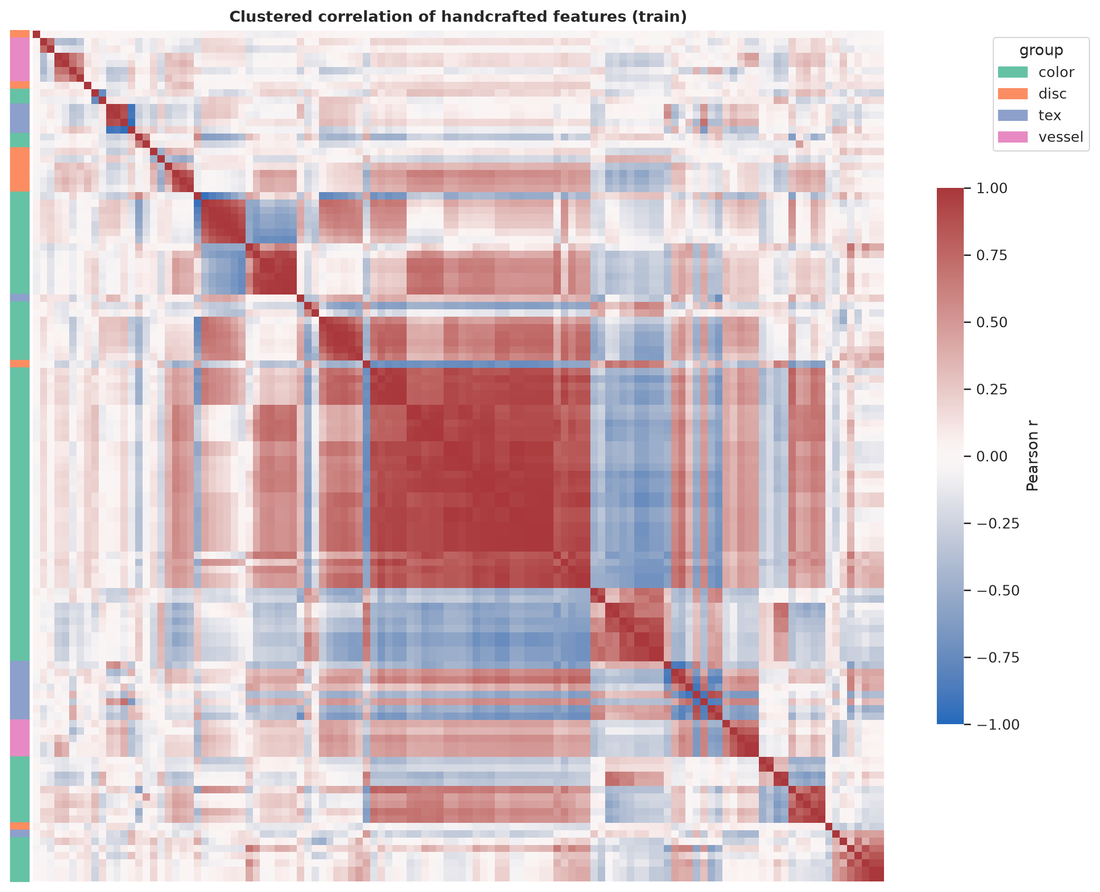

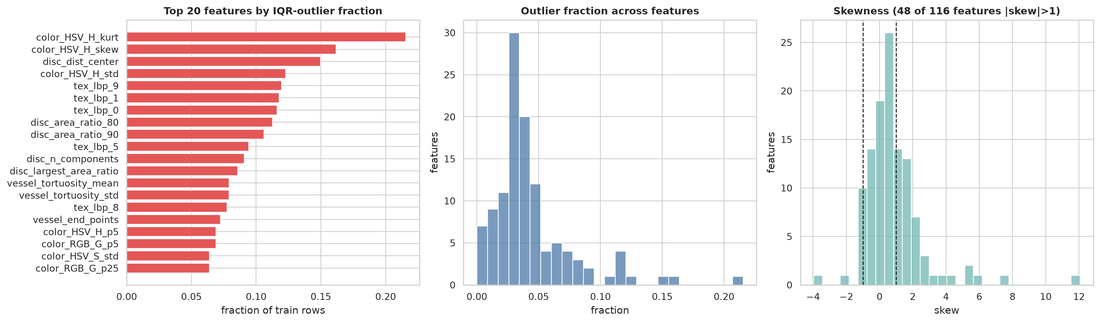

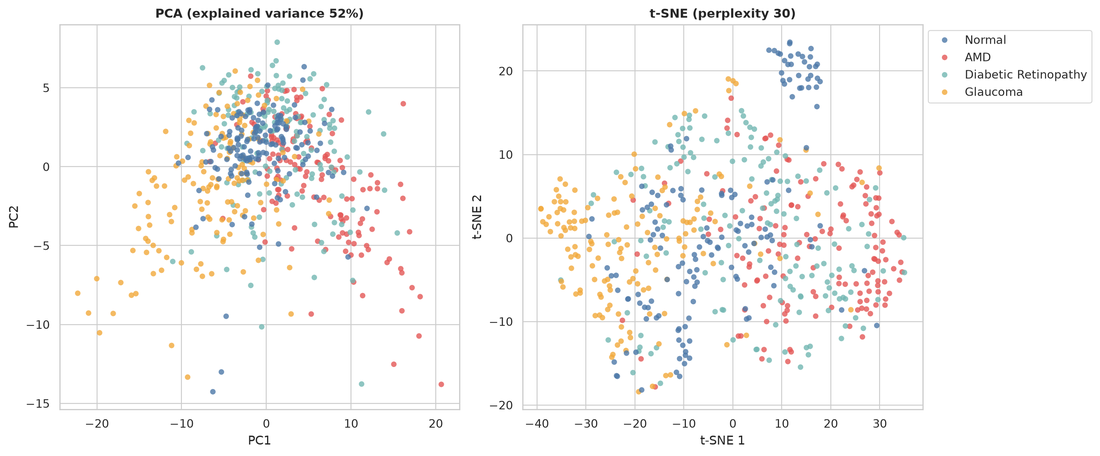

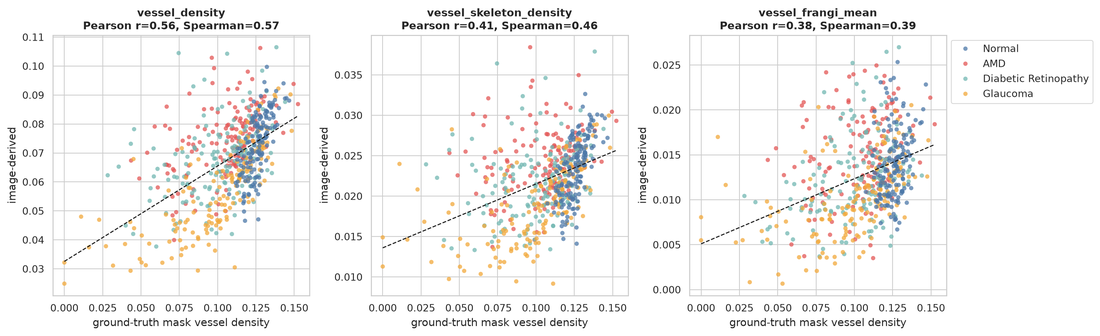

In [9]:
for f in ['feat_02_top12_distributions.png', 'feat_03_correlation_clustered.png', 'feat_04_outliers_skew.png', 'feat_05_pca_tsne.png', 'feat_06_vessel_vs_groundtruth.png']: fig(f, 1100)

## 5. Models

Six classifiers (Logistic Regression, Random Forest, SVM-RBF, KNN, XGBoost on GPU, Gaussian Naive Bayes), each inside the same preprocessing `Pipeline`, default hyperparameters,
on four feature sets: `handcrafted`, `handcrafted_norm`, `resnet`, `both`. Same procedure for all: 5-fold stratified CV on train, then one fit on all of train and one evaluation on the official test split.

In [10]:
s = pd.read_csv(T / "baseline_summary.csv")
s["CV F1"] = s.f1_macro_mean.map("{:.3f}".format) + " ± " + s.f1_macro_std.map("{:.3f}".format)
display(s.pivot(index="model", columns="experiment", values="CV F1")[["handcrafted", "handcrafted_norm", "resnet", "both"]])
print("test macro-F1:"); display(s.pivot(index="model", columns="experiment", values="test_f1_macro")[["handcrafted", "handcrafted_norm", "resnet", "both"]])
print("gap (CV F1 - test F1):"); display(s.pivot(index="model", columns="experiment", values="gap_f1_cv_minus_test")[["handcrafted", "handcrafted_norm", "resnet", "both"]])

experiment,handcrafted,handcrafted_norm,resnet,both
model,,,,
GaussianNB,0.577 ± 0.021,0.589 ± 0.037,0.608 ± 0.031,0.637 ± 0.036
KNN,0.610 ± 0.020,0.630 ± 0.032,0.580 ± 0.034,0.681 ± 0.037
LogisticRegression,0.677 ± 0.029,0.710 ± 0.041,0.657 ± 0.060,0.670 ± 0.025
RandomForest,0.670 ± 0.035,0.667 ± 0.054,0.635 ± 0.033,0.683 ± 0.044
SVM_RBF,0.653 ± 0.025,0.678 ± 0.036,0.652 ± 0.025,0.687 ± 0.032
XGBoost,0.673 ± 0.030,0.656 ± 0.028,0.632 ± 0.029,0.676 ± 0.026


test macro-F1:


experiment,handcrafted,handcrafted_norm,resnet,both
model,,,,
GaussianNB,0.429,0.459,0.424,0.433
KNN,0.538,0.562,0.533,0.526
LogisticRegression,0.646,0.542,0.557,0.555
RandomForest,0.583,0.577,0.516,0.529
SVM_RBF,0.592,0.590,0.542,0.548
XGBoost,0.538,0.628,0.555,0.553


gap (CV F1 - test F1):


experiment,handcrafted,handcrafted_norm,resnet,both
model,,,,
GaussianNB,0.148,0.130,0.184,0.204
KNN,0.072,0.068,0.047,0.155
LogisticRegression,0.031,0.168,0.100,0.115
RandomForest,0.088,0.090,0.119,0.154
SVM_RBF,0.061,0.088,0.111,0.139
XGBoost,0.135,0.028,0.077,0.123


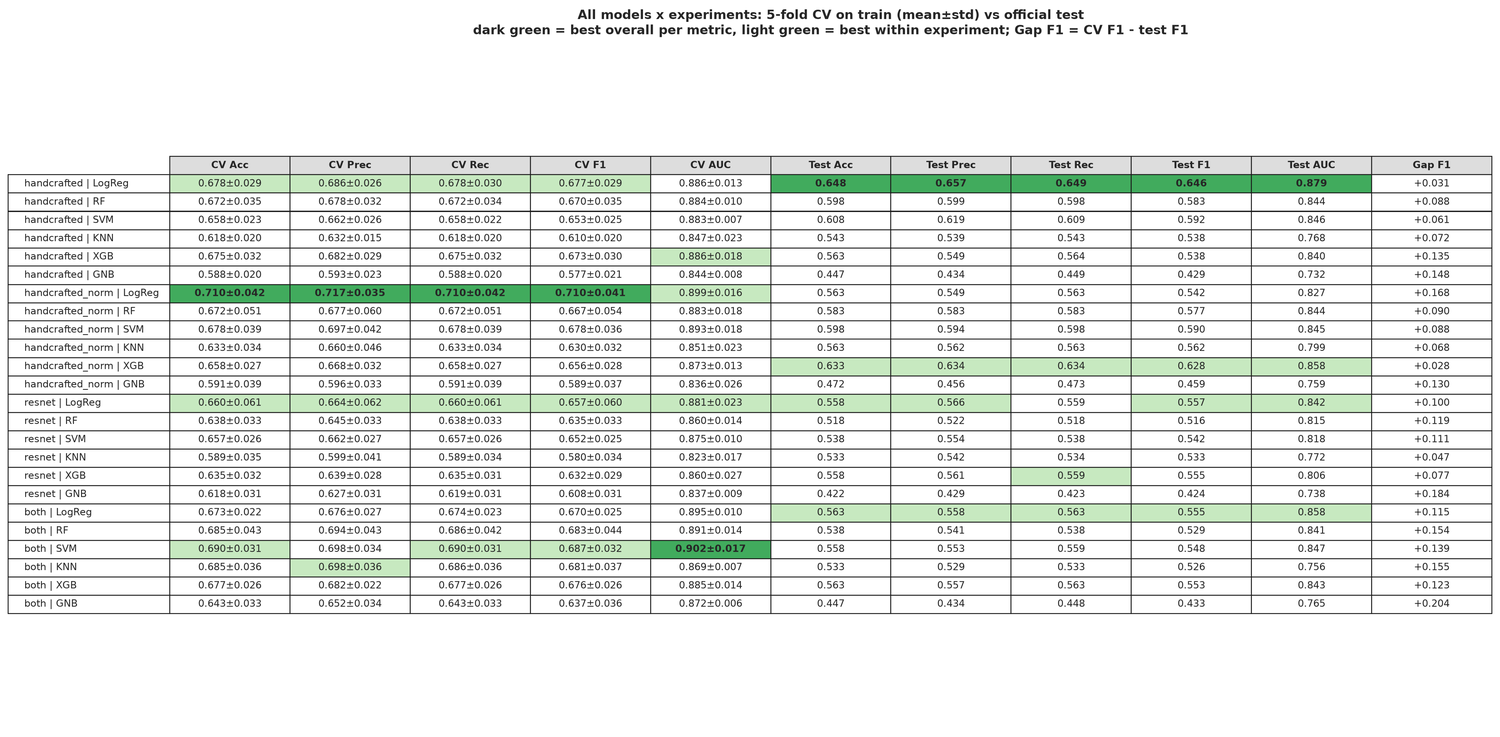

In [11]:
fig('cmp_01_comparison_table.png', 1500)

## 6. Comparison

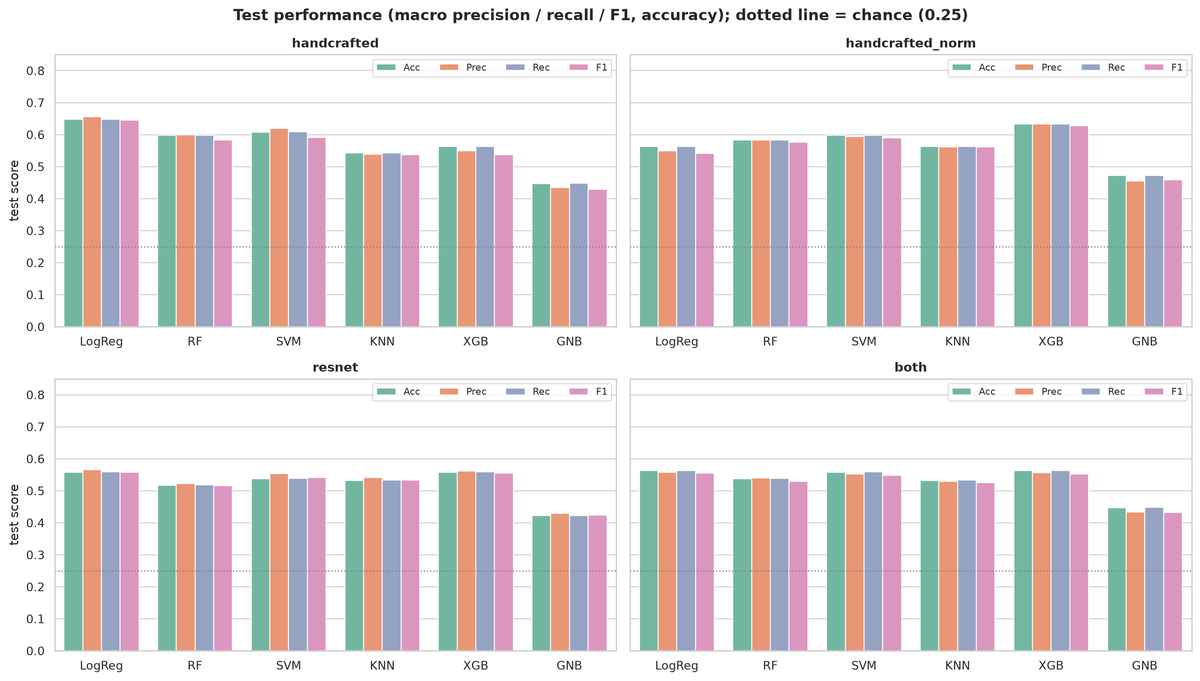

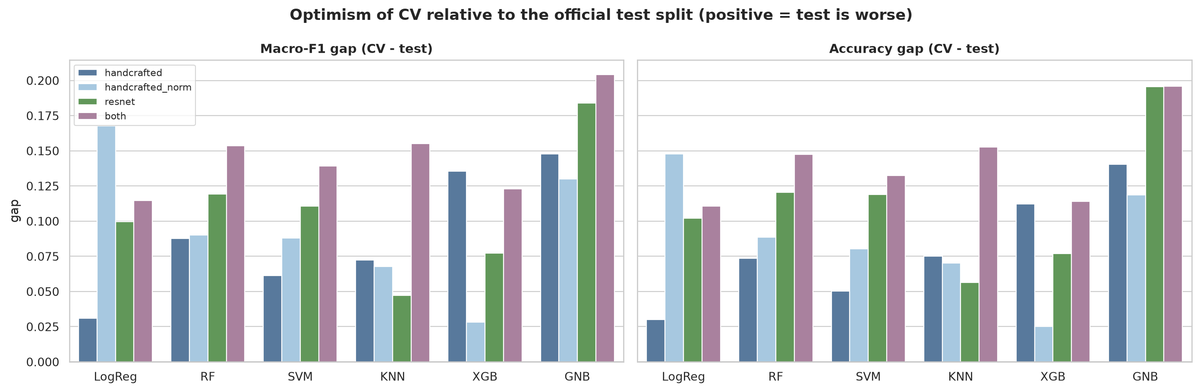

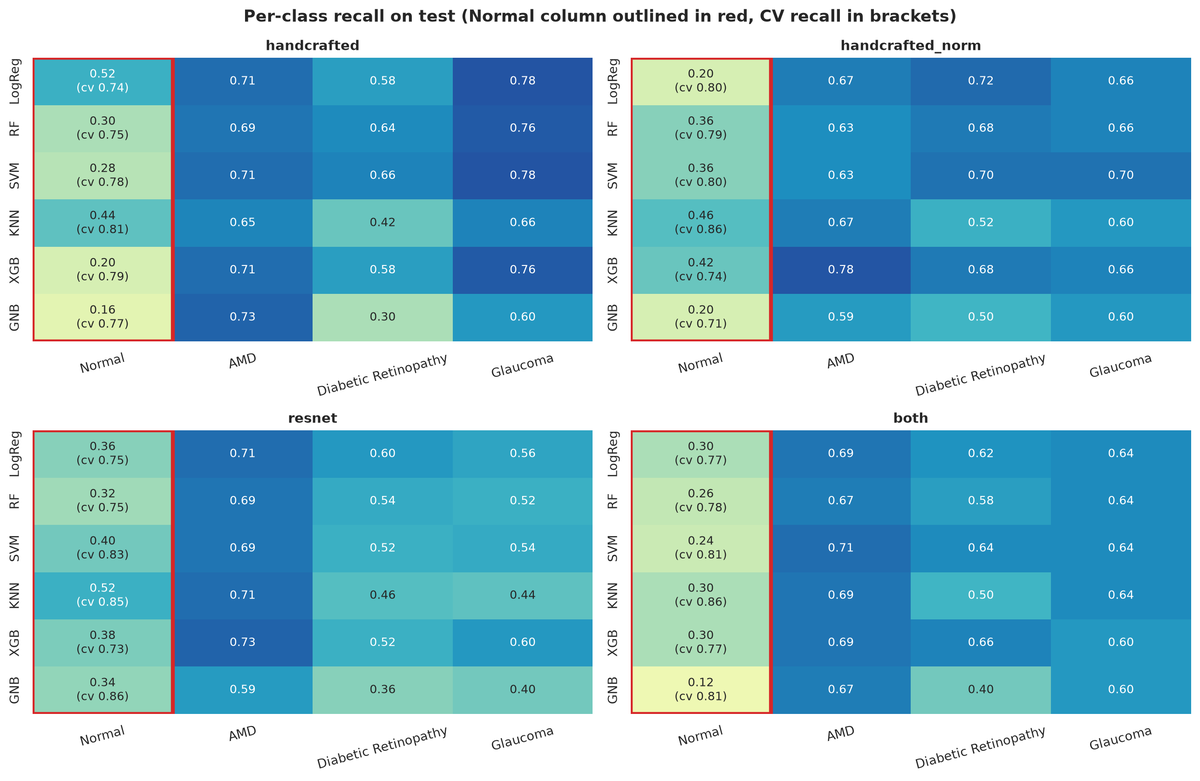

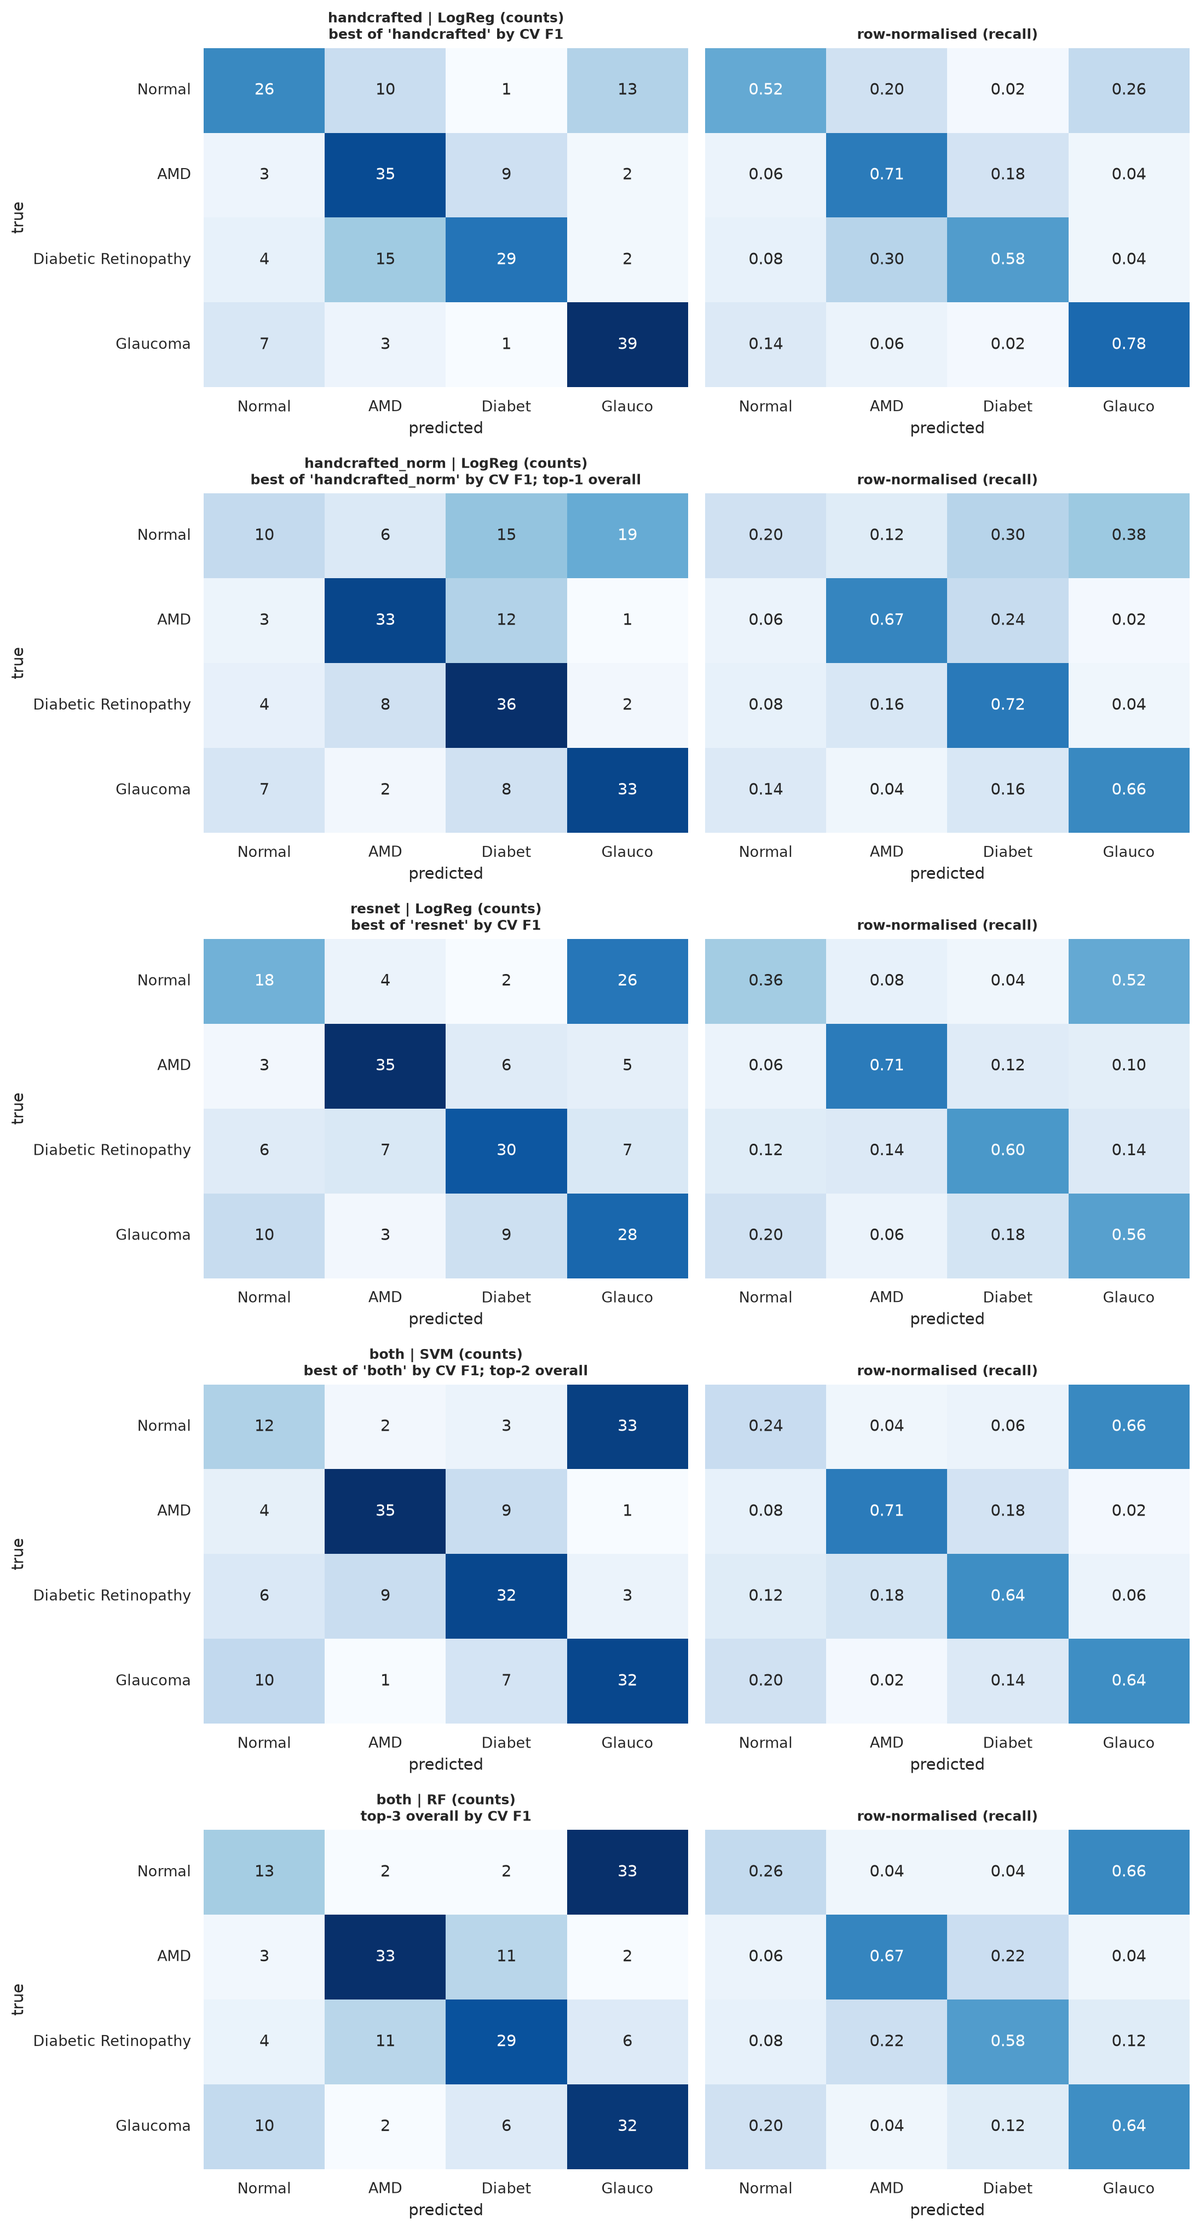

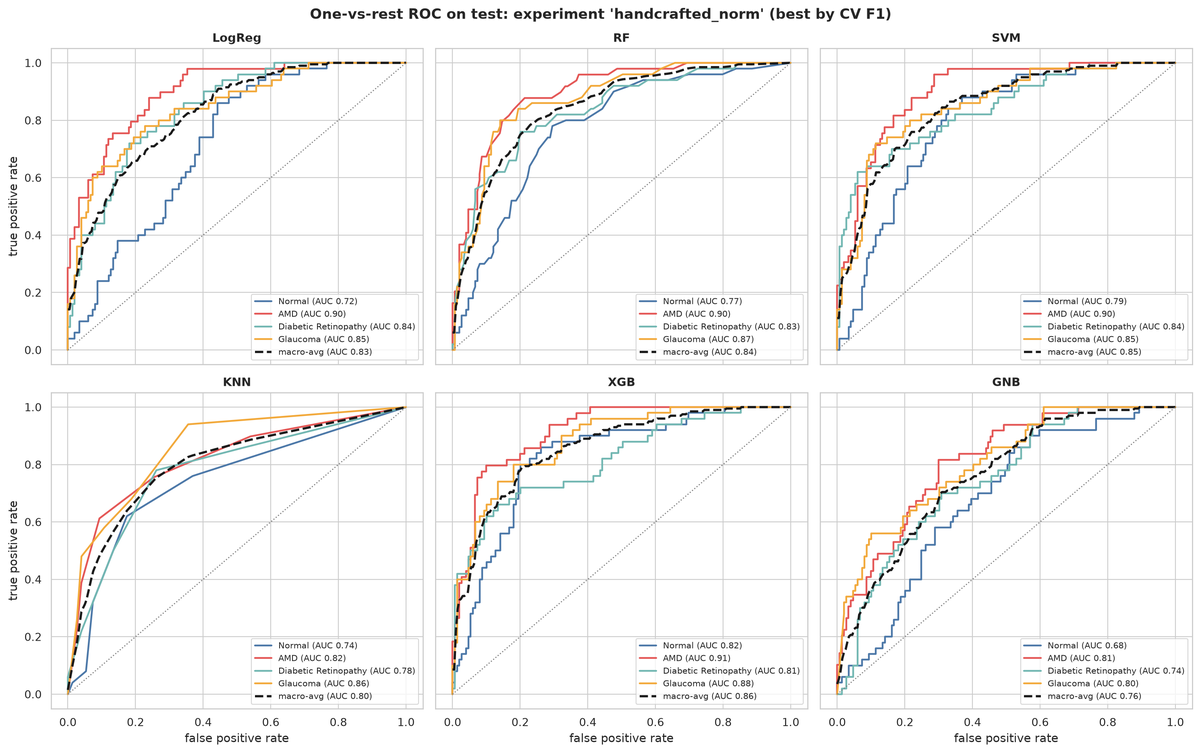

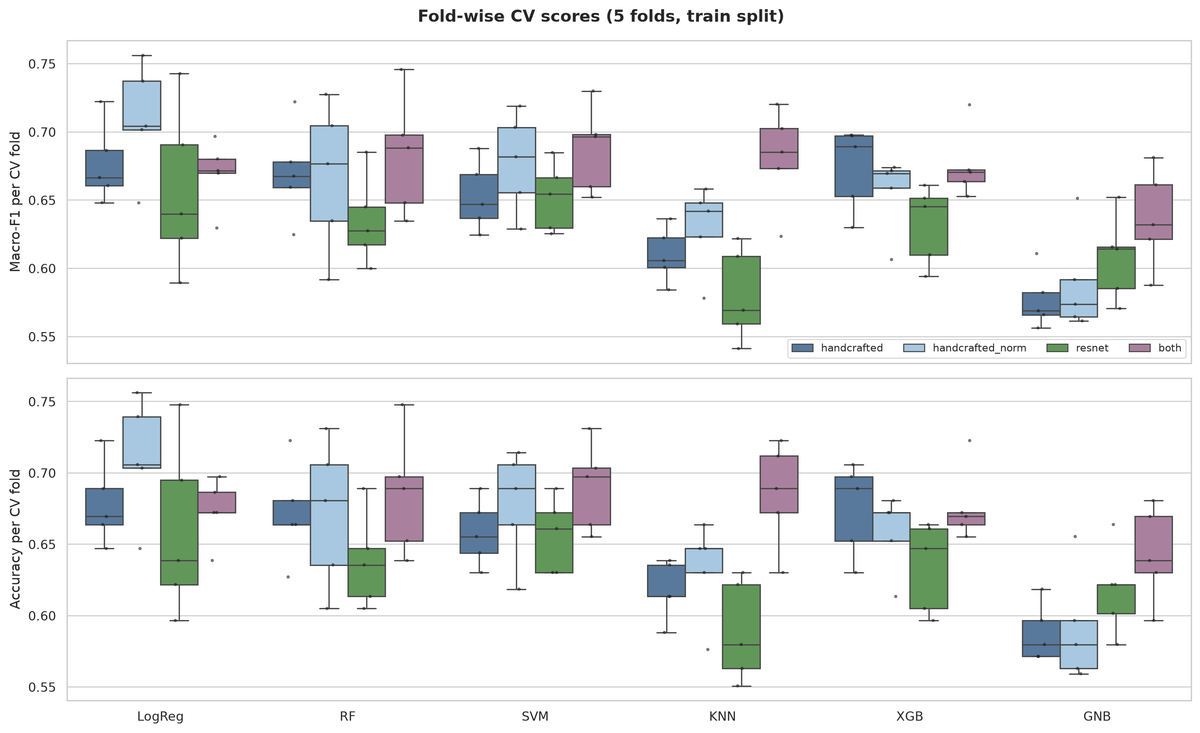

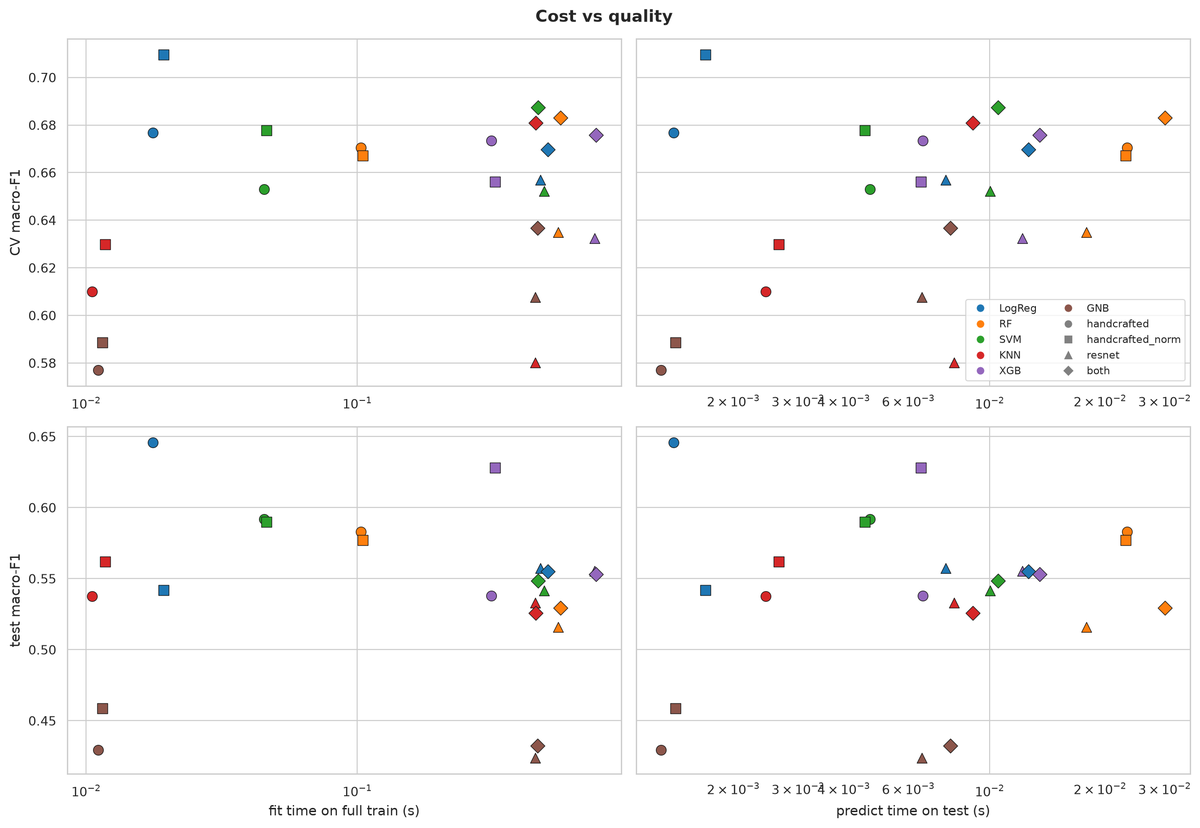

In [12]:
for f in ['cmp_02_test_metrics_bars.png', 'cmp_03_cv_test_gap.png', 'cmp_04_per_class_recall.png', 'cmp_05_confusion_matrices.png', 'cmp_06_roc_curves.png', 'cmp_07_cv_fold_boxplots.png', 'cmp_08_time_vs_f1.png']: fig(f, 1200)

Effect of per-image normalisation:


,model,cv_f1_base,test_f1_base,normal_recall_test_base,cv_f1_norm,test_f1_norm,normal_recall_test_norm,d_cv_f1,d_test_f1,d_normal_recall_test
0,LogReg,0.677,0.646,0.520,0.710,0.542,0.200,0.033,-0.104,-0.320
1,RF,0.670,0.583,0.300,0.667,0.577,0.360,-0.003,-0.006,0.060
2,SVM,0.653,0.592,0.280,0.678,0.590,0.360,0.025,-0.002,0.080
3,KNN,0.610,0.538,0.440,0.630,0.562,0.460,0.020,0.024,0.020
4,XGB,0.673,0.538,0.200,0.656,0.628,0.420,-0.017,0.090,0.220
5,GNB,0.577,0.429,0.160,0.589,0.459,0.200,0.012,0.029,0.040
6,MEAN,0.643,0.554,0.317,0.655,0.560,0.333,0.011,0.005,0.017


McNemar, top-2 by CV F1:


,model_A,model_B,both_correct,only_A_correct,only_B_correct,both_wrong,chi2_cc,p_chi2,p_exact,acc_A,acc_B
0,handcrafted_norm | LogisticRegression,both | SVM_RBF,86,26,25,62,0.000,1.000,1.000,0.563,0.558


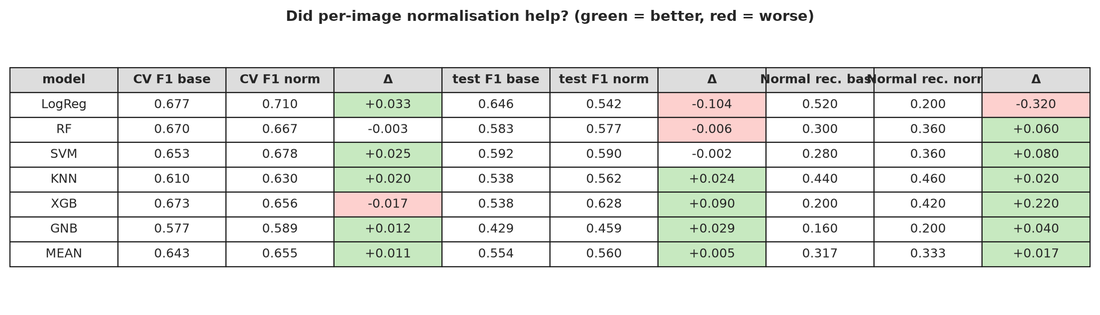

In [13]:
print('Effect of per-image normalisation:'); table('cmp_norm_effect.csv'); print('McNemar, top-2 by CV F1:'); table('cmp_mcnemar.csv'); fig('cmp_10_norm_effect.png', 1100)

In [14]:
md_file('results/comparison_summary.md')


All numbers come from `results/tables/baseline_*.csv` (script 06). CV = 5-fold stratified CV on the train split (594 images);
test = the official test split (199 images), used once. Identical preprocessing (median impute, RobustScaler, variance filter,
correlation filter 0.95, SelectKBest k=30) and identical folds for all 24 model x experiment combinations. Hyperparameters are still at defaults.

## Selected model (by CV macro-F1, not test)

**LogisticRegression** on **handcrafted_norm** features: CV macro-F1 0.710 ± 0.041, CV accuracy 0.710 ± 0.042.

Test result (single evaluation): accuracy 0.563, macro-F1 0.542, macro precision 0.549,
macro recall 0.563, ROC-AUC (OvR) 0.827. Gap CV - test macro-F1: +0.168.

| class | test precision | test recall | test F1 | CV recall |
|---|---|---|---|---|
| Normal | 0.42 | 0.20 | 0.27 | 0.80 |
| AMD | 0.67 | 0.67 | 0.67 | 0.66 |
| Diabetic Retinopathy | 0.51 | 0.72 | 0.60 | 0.60 |
| Glaucoma | 0.60 | 0.66 | 0.63 | 0.78 |

The CV lead of this model over the runner-up (SVM_RBF, both, CV F1 0.687) is 0.022,
smaller than one CV standard deviation (0.041), so the ranking among the top models is not statistically meaningful.
McNemar on test predictions of the top-2 by CV F1 (handcrafted_norm | LogisticRegression vs both | SVM_RBF): only-A-correct 26, only-B-correct 25,
exact p = 1.000, chi-square (continuity-corrected) p = 1.000; no significant difference at 0.05.

Best model per experiment by CV F1: handcrafted: LogisticRegression (CV 0.677, test 0.646); handcrafted_norm: LogisticRegression (CV 0.710, test 0.542); resnet: LogisticRegression (CV 0.657, test 0.557); both: SVM_RBF (CV 0.687, test 0.548).

## Most confused class pairs (test, mean over all 24 models; selected model in brackets)

- true Normal predicted as Glaucoma: 48.7% of that class [38.0%, 19 images]
- true Diabetic Retinopathy predicted as AMD: 23.2% of that class [16.0%, 8 images]
- true Glaucoma predicted as Normal: 18.7% of that class [14.0%, 7 images]
- true AMD predicted as Diabetic Retinopathy: 18.5% of that class [24.5%, 12 images]

Where true Normal test images go on average: Normal 32%, AMD 9%, Diabetic Retinopathy 10%, Glaucoma 49%.

## Normal-class source shift

Normal images in the train split come from a different source than the Normal images in the test split (EDA: a corner overlay glyph is present in 3% of
train Normal but 86% of test Normal images; the other classes show it at 80-98% in both splits).
- Mean blur score of Normal images: 4.09 in train vs 8.36 in test.
- Features whose Normal distribution differs between train and test (Mann-Whitney p < 0.001): 76/116 (handcrafted), 67/116 (handcrafted_norm).
  For AMD / DR / Glaucoma the counts are 0 / 0 / 2 (handcrafted) and 0 / 0 / 2 (normalised).
- Consequence: mean Normal recall over all 24 models is 0.79 in CV but 0.32 on test; the other three classes average 0.61 in CV vs 0.62 on test.
  By experiment (CV / test): handcrafted 0.77/0.32; handcrafted_norm 0.78/0.33; resnet 0.80/0.39; both 0.80/0.25.
  Models trained on the train Normal source learn "that look" as Normal; test Normal images look different and are mostly assigned to other classes.
- Per-image normalisation (illumination correction + channel standardisation) did not remove the shift (see `cmp_norm_effect.csv`): mean change over the six models in CV F1 +0.011, test F1 +0.005, Normal test recall +0.017.
- CV folds are drawn from the train split only, so every CV Normal image comes from the same source as the Normal images the model trained on; CV cannot see this shift; the CV-to-test gap (macro-F1) ranges from +0.028 to +0.204 across the 24 combinations.

## Limitations

- Test set size is 199 images; the standard error of the selected model's test accuracy is about ±0.035. Differences of a few points between models are within noise.
- One train/test partition and one CV seed; no repeated CV. Fold-wise CV F1 std is about 0.033.
- The shift is a property of the data source, not something the models can learn from this training set: reported test scores are therefore a pessimistic-but-honest estimate for images from the test source, and CV scores are optimistic for it. Which one matters for deployment depends on which source future images resemble.
- Hyperparameters, feature count (k=30) and the ResNet/both feature sets were not tuned here, so ResNet features are probably under-used.
- Earlier diagnostics (the Normal shift test, a quick random-forest probe) looked at test data and motivated creating the `handcrafted_norm` variant; no model or hyperparameter was selected from test results, and the selected model above is chosen on CV only, but the existence of that experiment is not test-blind.
- Vessel features are only moderately correlated with ground-truth vessel density (Pearson 0.56), colour features dominate feature rankings, and global intensity alone predicted class at ~66% in EDA, so part of the performance may be acquisition-style shortcuts rather than pathology.

## Note on regression metrics

MAE, MSE, RMSE and R² are regression metrics and do not apply to this 4-class classification task; accuracy, macro precision/recall/F1, per-class recall, confusion matrices and one-vs-rest ROC-AUC are used instead.

## 7. Tuning and ensembling

Top 3 model types of the best experiment (`handcrafted_norm`) were tuned with RandomizedSearchCV (40 draws, 5-fold, macro-F1; space includes `select__k`, scaler and correlation threshold); soft voting, stacking and bagging were built from them.
CV for tuned models and ensembles is **nested CV**. Selection used CV only; test is reported once.

In [15]:
ba = pd.read_csv(T / "tune_before_after.csv")
display(ba[["stage", "candidate", "cv_f1_mean", "cv_f1_std", "test_f1_macro", "test_accuracy", "cv_recall_Normal", "test_recall_Normal", "cv_verdict", "test_verdict"]])
print("gain over reference vs CV noise:"); table("tune_gain_vs_noise.csv")
print(json.dumps(json.load(open(ROOT / "results/best_hyperparameters.json"))["final_model"], indent=1))

,stage,candidate,cv_f1_mean,cv_f1_std,test_f1_macro,test_accuracy,cv_recall_Normal,test_recall_Normal,cv_verdict,test_verdict
0,baseline,baseline_LogisticRegression,0.710,0.041,0.542,0.563,0.800,0.200,NaN,NaN
1,baseline,baseline_RandomForest,0.667,0.054,0.577,0.583,0.787,0.360,NaN,NaN
2,baseline,baseline_SVM_RBF,0.678,0.036,0.590,0.598,0.800,0.360,NaN,NaN
3,tuned,tuned_LogisticRegression,0.701,0.036,0.546,0.568,0.780,0.220,no CV gain,positive on test but CI includes 0
4,tuned,tuned_RandomForest,0.689,0.015,0.560,0.578,0.800,0.240,gain within CV noise,does not survive on test
5,tuned,tuned_SVM_RBF,0.696,0.028,0.609,0.613,0.807,0.420,gain within CV noise,positive on test but CI includes 0
6,ensemble,bagging,0.706,0.028,0.578,0.593,0.793,0.260,no CV gain,positive on test but CI includes 0
7,ensemble,stacking,0.716,0.031,0.600,0.623,0.753,0.240,gain within CV noise,survives on test (CI > 0)
8,ensemble,voting,0.721,0.044,0.582,0.603,0.800,0.240,gain within CV noise,positive on test but CI includes 0


gain over reference vs CV noise:


,candidate,reference,cv_gain_f1,reference_cv_std,gain_over_ref_std,paired_fold_diff_mean,paired_fold_diff_std,folds_improved,test_gain_f1,test_gain_ci_low,test_gain_ci_high,normal_recall_gain_test,test_verdict,cv_verdict
0,tuned_LogisticRegression,baseline_LogisticRegression,-0.009,0.041,-0.208,-0.009,0.052,3,0.005,-0.053,0.063,0.020,positive on test but CI includes 0,no CV gain
1,tuned_SVM_RBF,baseline_SVM_RBF,0.018,0.036,0.508,0.018,0.042,3,0.019,-0.050,0.089,0.060,positive on test but CI includes 0,gain within CV noise
2,tuned_RandomForest,baseline_RandomForest,0.022,0.054,0.406,0.022,0.049,3,-0.017,-0.073,0.040,-0.120,does not survive on test,gain within CV noise
3,voting,baseline_LogisticRegression,0.011,0.041,0.274,0.011,0.066,3,0.040,-0.017,0.097,0.040,positive on test but CI includes 0,gain within CV noise
4,stacking,baseline_LogisticRegression,0.007,0.041,0.162,0.007,0.066,2,0.058,0.001,0.115,0.040,survives on test (CI > 0),gain within CV noise
5,bagging,baseline_LogisticRegression,-0.004,0.041,-0.087,-0.004,0.058,2,0.036,-0.018,0.091,0.060,positive on test but CI includes 0,no CV gain


{
 "candidate": "voting",
 "cv_f1": 0.7208464388875477,
 "cv_f1_std": 0.04440740653777269,
 "cv_estimate": "nested 5-fold CV"
}


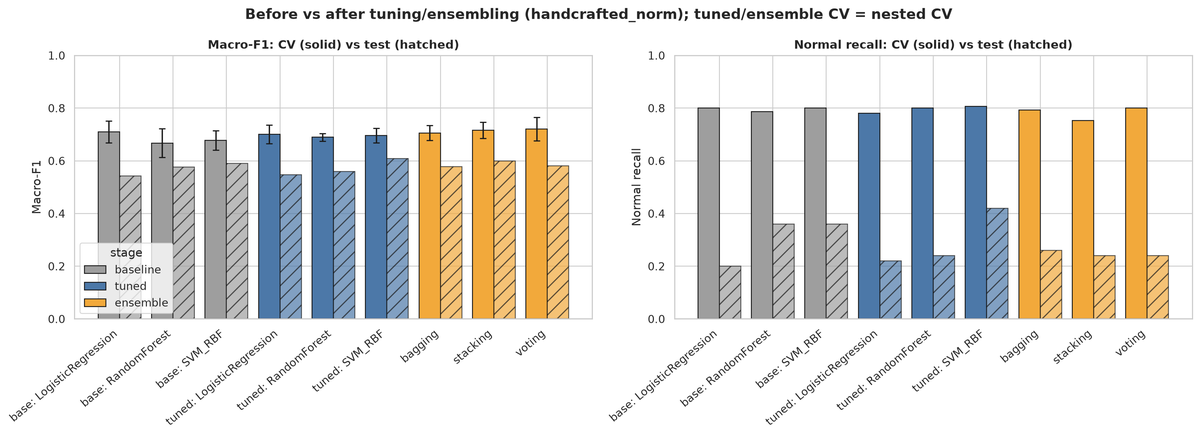

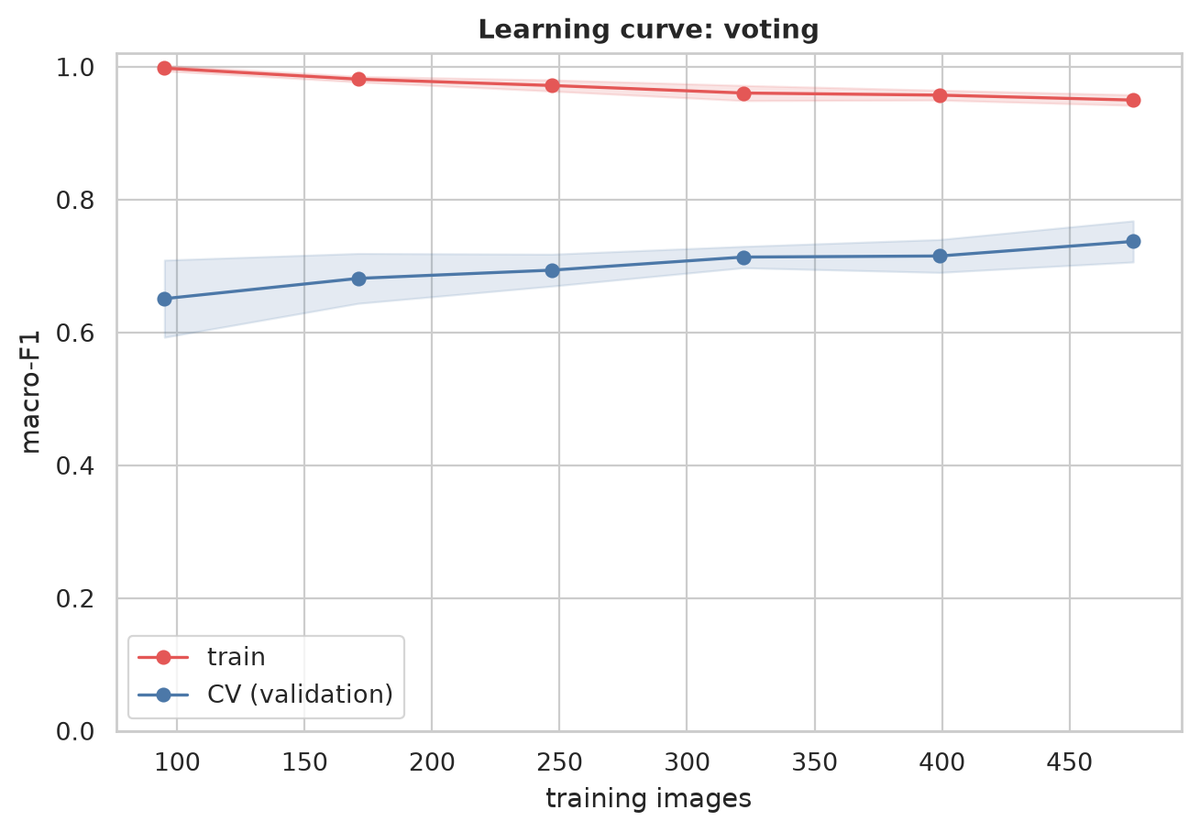

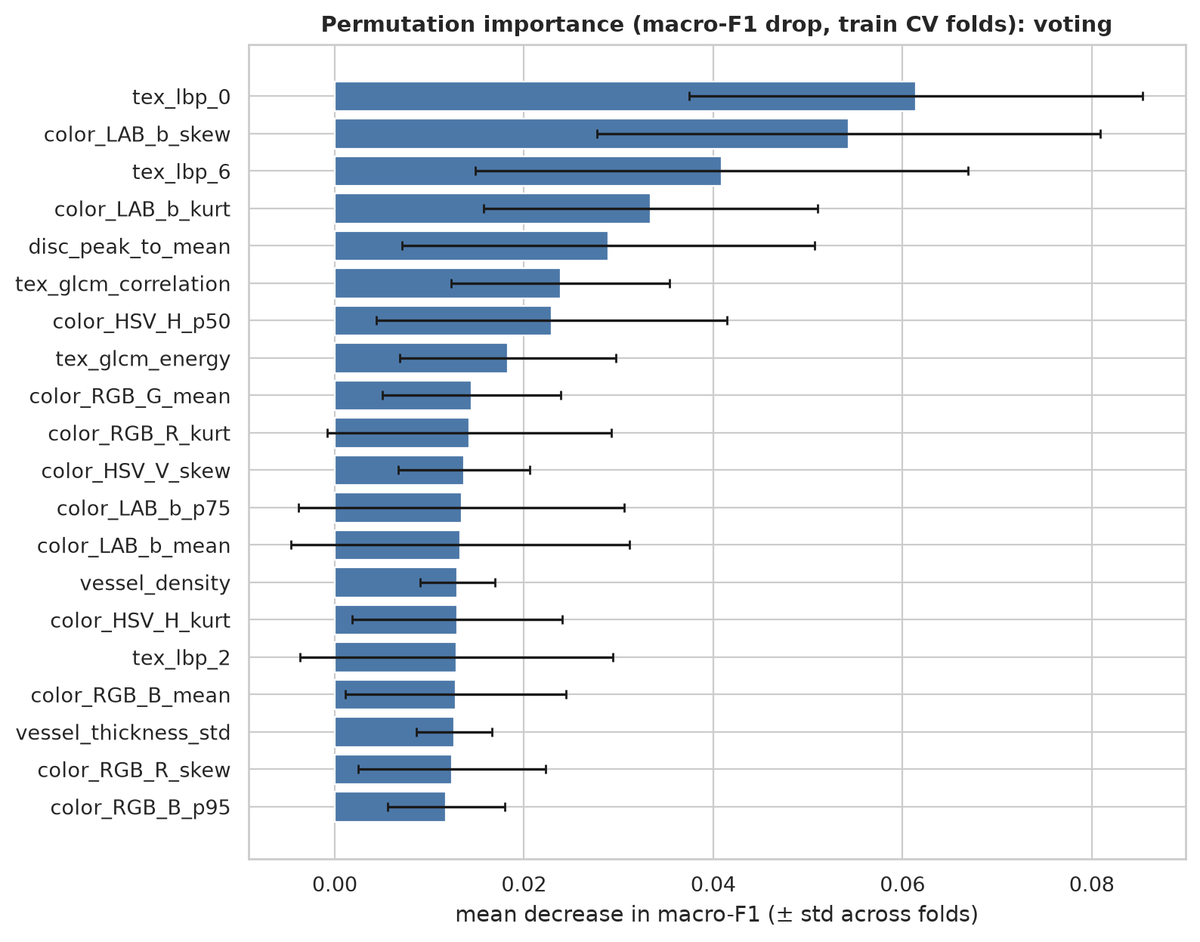

In [16]:
for f in ['tune_01_before_after.png', 'tune_02_learning_curve.png', 'tune_03_permutation_importance.png']: fig(f, 1200)

In [17]:
md_file('results/tuning_summary.md')


Experiment: **handcrafted_norm** (best baseline CV macro-F1). Tuned models (top 3 by baseline CV F1 in that experiment): LogisticRegression, SVM_RBF, RandomForest.
Each was tuned with RandomizedSearchCV (40 draws, 5-fold stratified CV, macro-F1) over its hyperparameters, `select__k`, the scaler and the
correlation-filter threshold. Ensembles (soft voting, stacking with a logistic-regression meta-learner, bagging of SVM_RBF) were built from the tuned models.
CV for every tuned model and ensemble is **nested CV** (searches are re-run inside each outer training fold), so it is not inflated by the search;
baseline CV numbers are the plain 5-fold CV from script 06 on the same folds. Test was used once at the end.

## Did tuning help?

- tuned_LogisticRegression: CV F1 -0.009 (-0.21 reference CV std; 3/5 folds improved), test F1 +0.005 (95% bootstrap CI -0.053 to +0.063) -> no CV gain; positive on test but CI includes 0
- tuned_SVM_RBF: CV F1 +0.018 (+0.51 reference CV std; 3/5 folds improved), test F1 +0.019 (95% bootstrap CI -0.050 to +0.089) -> gain within CV noise; positive on test but CI includes 0
- tuned_RandomForest: CV F1 +0.022 (+0.41 reference CV std; 3/5 folds improved), test F1 -0.017 (95% bootstrap CI -0.073 to +0.040) -> gain within CV noise; does not survive on test

Mean CV gain of tuning over the three baselines: +0.011 macro-F1 (mean reference CV std 0.044); mean test gain +0.002.

## Did ensembling help?

Reference for ensembles = best baseline by CV (LogisticRegression, CV F1 0.710 ± 0.041, test F1 0.542).

- voting: CV F1 +0.011 (+0.27 reference CV std; 3/5 folds improved), test F1 +0.040 (95% bootstrap CI -0.017 to +0.097) -> gain within CV noise; positive on test but CI includes 0
- stacking: CV F1 +0.007 (+0.16 reference CV std; 2/5 folds improved), test F1 +0.058 (95% bootstrap CI +0.001 to +0.115) -> gain within CV noise; survives on test (CI > 0)
- bagging: CV F1 -0.004 (-0.09 reference CV std; 2/5 folds improved), test F1 +0.036 (95% bootstrap CI -0.018 to +0.091) -> no CV gain; positive on test but CI includes 0

## Verdict on noise

Largest CV gain: tuned_RandomForest (+0.022, +0.41 reference CV std). No gain exceeds one CV standard deviation of the baseline, so every improvement is within CV noise. 1 of 6 candidates show a test gain whose bootstrap CI excludes 0. That result is borderline (lower CI bound close to 0) and is one of six comparisons at 95%, where about 0.3 false positives are expected by chance; it is not backed by a CV gain beyond noise.

## Final model (selected by CV only)

**voting** with 0.721 ± 0.044 CV macro-F1 (nested 5-fold CV). Test (single evaluation): accuracy 0.603,
macro-F1 0.582, ROC-AUC 0.866; per-class test recall: Normal 0.24, AMD 0.67, Diabetic Retinopathy 0.70, Glaucoma 0.80.
Saved: `models/best_model.joblib` (fitted estimator; every member includes the full preprocessing Pipeline), `models/classes.json`,
`models/best_model_meta.json` (feature set `handcrafted_norm`, feature columns and extractor `src.features.extract_handcrafted_norm`), `results/best_hyperparameters.json`.
Top permutation-importance features (train CV folds): tex_lbp_0 (0.061), color_LAB_b_skew (0.054), tex_lbp_6 (0.041), color_LAB_b_kurt (0.033), disc_peak_to_mean (0.029).

## Caveats

- **Normal source shift.** Normal training images come from a different source than Normal test images (see `comparison_summary.md`). CV cannot see this, so any CV gain
  may not transfer to test: CV Normal recall of the final model is 0.80 versus 0.24 on test. Selection by CV therefore cannot fix, and may even
  reward, fitting the train-source Normal look.
- The baseline CV score used as reference for LogisticRegression/ensembles is itself the maximum of 24 baseline CV scores, so it is slightly optimistic (winner's curse); the nested estimates of tuned models are not.
- Of the 10 most important features (permutation importance on train CV folds), 6 differ significantly between train and test Normal images (p < 0.001): tex_lbp_0, color_LAB_b_skew, color_LAB_b_kurt, disc_peak_to_mean, tex_glcm_correlation, color_HSV_H_p50. Importance computed on train therefore partly reflects the train-source Normal look.
- Tuned models are chosen from 40 draws on 594 images; differences between top configurations are small relative to fold-to-fold variation (inner CV std about 0.031).
- The test set has 199 images; a one-point change in macro-F1 is a few images. Bootstrap CIs above are wide for that reason.
- The CV selection of the final model compares candidates whose CV estimates differ by less than one standard deviation, so the choice among them is close to arbitrary.
- Bagging a stable linear model or SVM rarely helps: it reduces variance, which these models have little of.

## 8. Ablation and source shift

Feature-group ablation, the Normal-class source-shift analysis (train-vs-test classifier AUC), robustness to blur / brightness / noise, and the most confident errors.

,config,n_features,cv_f1_mean,cv_f1_std,test_f1,test_acc
0,all (handcrafted_norm),116,0.739,0.026,0.582,0.603
1,only color,81,0.671,0.057,0.557,0.563
2,only tex,14,0.623,0.040,0.483,0.508
3,only vessel,11,0.537,0.038,0.414,0.422
4,only disc,10,0.531,0.035,0.464,0.467
5,without color,35,0.677,0.034,0.519,0.543
6,without tex,102,0.695,0.027,0.580,0.588
7,without vessel,105,0.730,0.034,0.582,0.593
8,without disc,106,0.742,0.038,0.567,0.593
9,ResNet50 only,2048,0.708,0.036,0.582,0.593


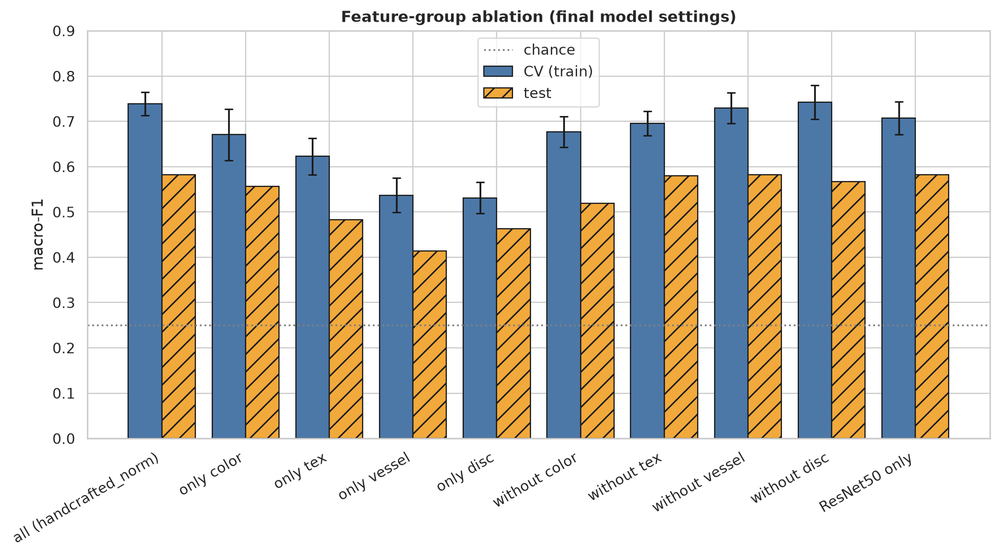

In [18]:
table('abl_feature_groups.csv'); fig('abl_01_feature_groups.png', 1000)

Normal excluded:


,model,macro_f1_3cls,recall_AMD,recall_Diabetic Retinopathy,recall_Glaucoma,cv_recall_AMD,cv_recall_Diabetic Retinopathy,cv_recall_Glaucoma,cv_macro_f1_3cls
0,"final 4-class, scored on non-Normal test images",0.760,0.673,0.700,0.800,0.694,0.653,0.793,NaN
1,3-class (Normal removed from train and test),0.772,0.694,0.740,0.880,0.729,0.713,0.820,0.753


Normal vs rest:


,split,auc_normal_vs_rest,precision,recall,f1,n_normal,n_pred_normal
0,"CV (train, out-of-fold)",0.939,0.737,0.820,0.776,150,167
1,test,0.792,0.480,0.240,0.320,50,25


train-vs-test AUC (0.5 = no shift):


,class,feature_set,model,train_vs_test_auc,auc_std,n_train,n_test
0,Normal,handcrafted,LogReg,0.976,0.013,150,50
1,Normal,handcrafted,RandomForest,0.979,0.016,150,50
2,Normal,handcrafted_norm,LogReg,0.963,0.022,150,50
3,Normal,handcrafted_norm,RandomForest,0.965,0.018,150,50
4,Normal,resnet,LogReg,0.978,0.021,150,50
5,Normal,resnet,RandomForest,0.969,0.023,150,50
6,AMD,handcrafted,LogReg,0.478,0.132,144,49
7,AMD,handcrafted,RandomForest,0.495,0.117,144,49
8,AMD,handcrafted_norm,LogReg,0.503,0.106,144,49
9,AMD,handcrafted_norm,RandomForest,0.482,0.102,144,49


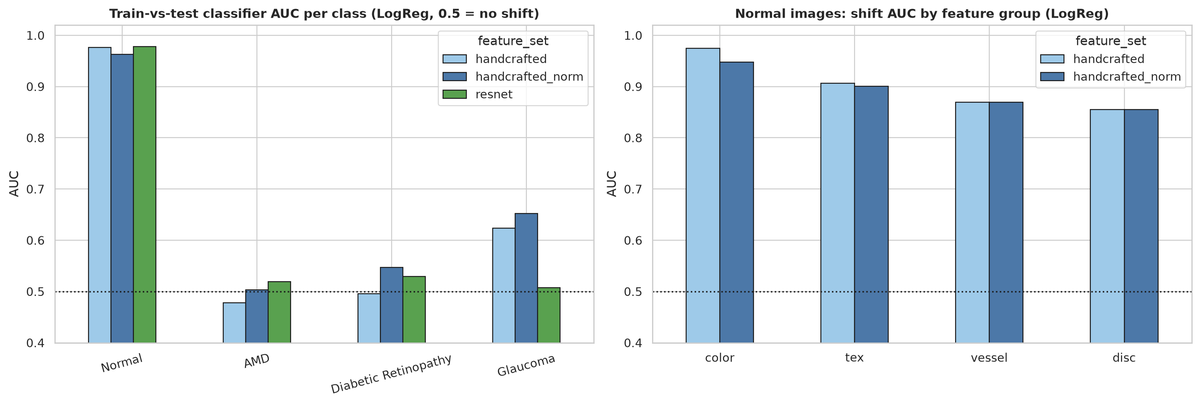

In [19]:
print('Normal excluded:'); table('abl_normal_excluded.csv'); print('Normal vs rest:'); table('abl_normal_vs_rest.csv'); print('train-vs-test AUC (0.5 = no shift):'); table('abl_train_vs_test_auc.csv'); fig('abl_02_source_shift.png', 1200)

,perturbation,macro_f1,accuracy,recall_Normal,recall_AMD,recall_Diabetic Retinopathy,recall_Glaucoma,share_predicted_Normal,largest_predicted_class_share,f1_drop_vs_clean
0,clean,0.582,0.603,0.240,0.673,0.700,0.800,0.126,0.317,0.000
1,blur sigma=2,0.544,0.543,0.420,0.531,0.780,0.440,0.196,0.467,0.038
2,blur sigma=4,0.387,0.407,0.540,0.163,0.660,0.260,0.382,0.497,0.195
3,brightness x0.7,0.582,0.583,0.380,0.612,0.660,0.680,0.231,0.302,-0.000
4,brightness x1.3,0.537,0.593,0.080,0.837,0.620,0.840,0.050,0.357,0.045
5,noise sigma=10,0.315,0.422,0.800,0.082,0.000,0.800,0.382,0.598,0.267
6,noise sigma=20,0.120,0.261,0.040,0.000,0.000,1.000,0.010,0.990,0.461


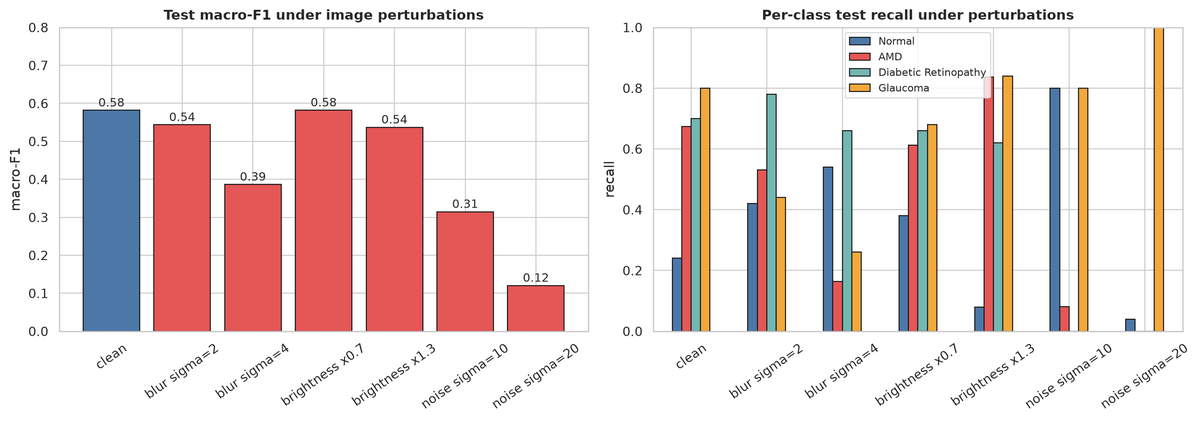

,image_id,true,predicted,confidence,p_true_class,involves_Normal
0,test_163_N,Normal,Glaucoma,0.953,0.029,True
1,test_155_N,Normal,Glaucoma,0.916,0.041,True
2,test_164_N,Normal,Glaucoma,0.872,0.093,True
3,test_118_G,Glaucoma,Normal,0.854,0.075,True
4,test_60_D,Diabetic Retinopathy,AMD,0.799,0.177,False
5,test_146_G,Glaucoma,Normal,0.795,0.090,True
6,test_111_G,Glaucoma,Diabetic Retinopathy,0.767,0.131,False
7,test_183_N,Normal,Glaucoma,0.766,0.151,True
8,test_142_G,Glaucoma,Normal,0.755,0.197,True
9,test_36_A,AMD,Diabetic Retinopathy,0.730,0.213,False


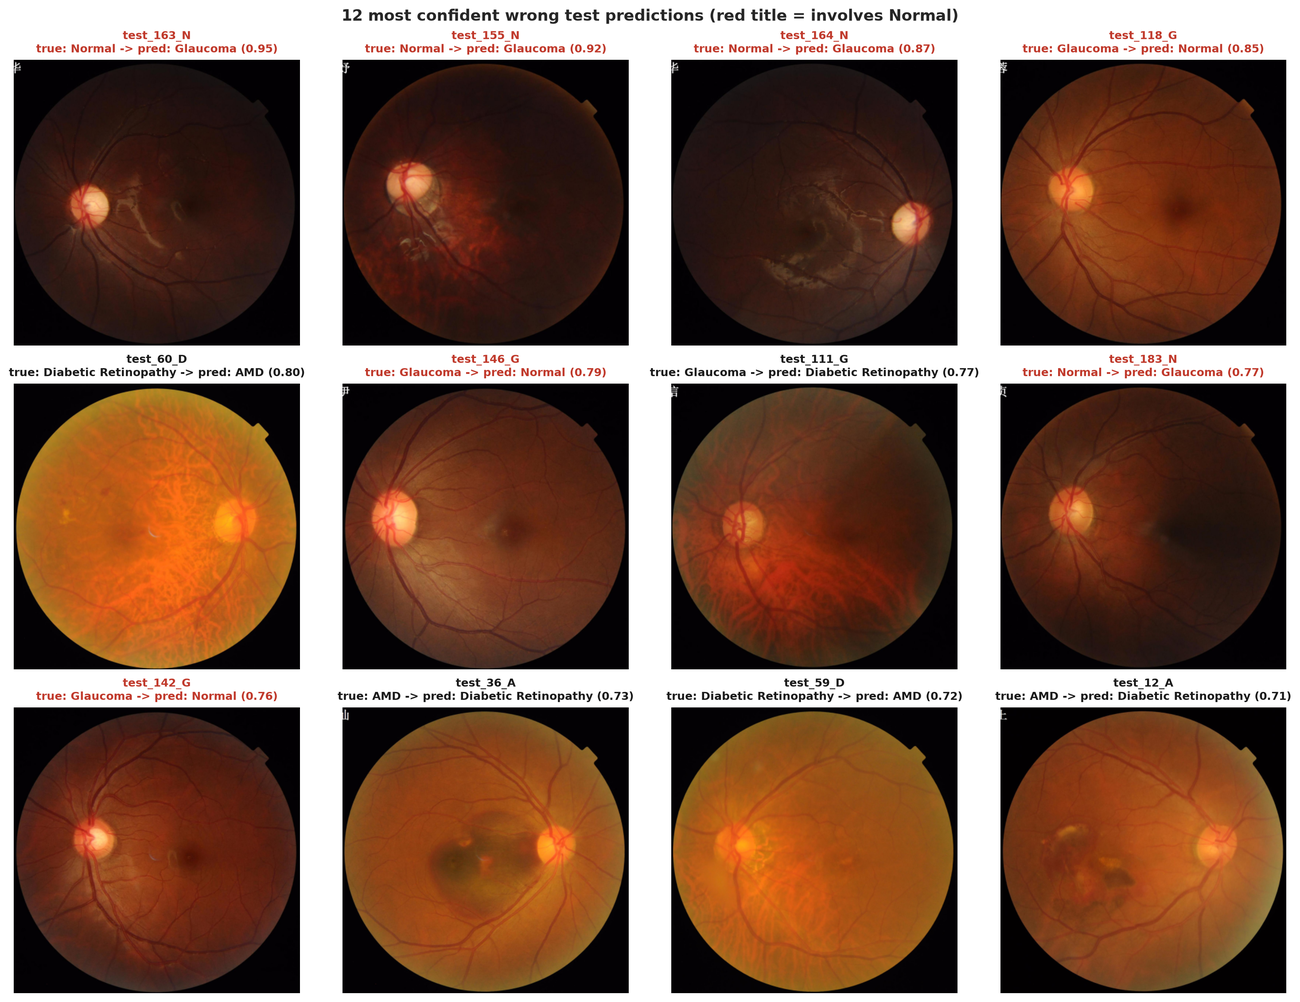

In [20]:
table('abl_robustness.csv'); fig('abl_03_robustness.png', 1200); table('abl_top_errors.csv'); fig('abl_04_top_errors.png', 1300)

In [21]:
md_file('results/ablation_summary.md')


Final model: **voting** (soft-voting ensemble of tuned LogReg / SVM / RF pipelines) on **handcrafted_norm** features; CV macro-F1 0.721 (nested), test macro-F1 0.582.
Ablation refits clones of the final model's hyperparameters. Those were tuned on all features and on this same train data, so the ablation CV scores are not nested (the full-feature CV here, 0.739, is about 0.018 above the nested 0.721); compare configurations with each other, not with the nested figure, and subsets are slightly disadvantaged. Test numbers are reported, never used for selection.

## 1. Feature-group ablation (CV / test macro-F1)

| config                 |   n_features | CV            |   test |
|:-----------------------|-------------:|:--------------|-------:|
| all (handcrafted_norm) |          116 | 0.739 ± 0.026 |  0.582 |
| only color             |           81 | 0.671 ± 0.057 |  0.557 |
| only tex               |           14 | 0.623 ± 0.040 |  0.483 |
| only vessel            |           11 | 0.537 ± 0.038 |  0.414 |
| only disc              |           10 | 0.531 ± 0.035 |  0.464 |
| without color          |           35 | 0.677 ± 0.034 |  0.519 |
| without tex            |          102 | 0.695 ± 0.027 |  0.58  |
| without vessel         |          105 | 0.730 ± 0.034 |  0.582 |
| without disc           |          106 | 0.742 ± 0.038 |  0.567 |
| ResNet50 only          |         2048 | 0.708 ± 0.036 |  0.582 |

- Strongest single group by CV: **only color** (CV 0.671); removing a group hurts most for **without color** (CV 0.677 vs 0.739 with everything).
- Differences between most configurations are within the CV standard deviation (about 0.036); only large drops should be read as real.
- ResNet50 alone: CV 0.708, test 0.582.

## 2. Source shift of the Normal class

**Normal excluded.** Scoring the final 4-class model on the 149 non-Normal test images (predicting Normal counts as an error) gives macro-F1 over the three classes of 0.760
(recall AMD 0.67, DR 0.70, Glaucoma 0.80; CV recall 0.69 / 0.65 / 0.79).
A 3-class model trained without any Normal images reaches CV macro-F1 0.753 and test macro-F1 0.772 (test recall 0.69 / 0.74 / 0.88),
so the three disease classes transfer from train to test much better than Normal does.

**Normal-vs-rest** (final model, P(Normal) as score): CV (out-of-fold) AUC 0.939, precision 0.74, recall 0.82, F1 0.78; test AUC 0.792, precision 0.48, recall 0.24, F1 0.32
(the model predicts Normal for 25 test images; 50 are truly Normal). True Normal test images are predicted as: Glaucoma 17, Normal 12, Diabetic Retinopathy 11, AMD 10.

**Train-vs-test classifier (images of a single class; AUC 0.5 = train and test are indistinguishable).** For Normal, a LogReg separates train from test with AUC
0.976 (handcrafted), 0.963 (handcrafted_norm), 0.978 (ResNet50); RandomForest 0.979 / 0.965 / 0.969.
The highest AUC among the other three classes (controls) is 0.623 / 0.652 / 0.529. Full table: `abl_train_vs_test_auc.csv`.

**Which feature groups carry the shift** (Normal, LogReg AUC): handcrafted_norm: color 0.948, tex 0.900, vessel 0.870, disc 0.855; handcrafted: color 0.975, tex 0.907, vessel 0.870, disc 0.855.
Most shifted single features (handcrafted_norm, single-feature AUC of train vs test; below 0.5 means lower in train): tex_lbp_9 (0.92), tex_lbp_3 (0.09), color_HSV_V_p25 (0.91), tex_lbp_1 (0.91), tex_lbp_5 (0.11).

## 3. Robustness (test images degraded, features re-extracted, final model unchanged)

| perturbation    |   macro_f1 |   accuracy |   recall_Normal |   share_predicted_Normal |   f1_drop_vs_clean |
|:----------------|-----------:|-----------:|----------------:|-------------------------:|-------------------:|
| clean           |      0.582 |      0.603 |            0.24 |                    0.126 |              0     |
| blur sigma=2    |      0.544 |      0.543 |            0.42 |                    0.196 |              0.038 |
| blur sigma=4    |      0.387 |      0.407 |            0.54 |                    0.382 |              0.195 |
| brightness x0.7 |      0.582 |      0.583 |            0.38 |                    0.231 |             -0     |
| brightness x1.3 |      0.537 |      0.593 |            0.08 |                    0.05  |              0.045 |
| noise sigma=10  |      0.315 |      0.422 |            0.8  |                    0.382 |              0.267 |
| noise sigma=20  |      0.12  |      0.261 |            0.04 |                    0.01  |              0.461 |

Largest drop: **noise sigma=20** (+0.461 macro-F1). Perturbation definitions: Gaussian blur at 512 px scale; multiplicative brightness (so the black border stays black);
Gaussian noise on the retina only. The model was never trained with such perturbations. Blur raises Normal recall from 0.24 to 0.42 (sigma 2) and 0.54 (sigma 4) while lowering macro-F1, consistent with the model having learned 'blurrier image = Normal' from the blurrier train Normal images (blur score 4.1 vs 8.4 in test). Noise destroys the texture features: at sigma=20 macro-F1 is 0.12 (chance is 0.25) and 99% of predictions fall into one class; the model is not robust to sensor noise and should not be trusted on noisy or heavily compressed images.

## 4. Error analysis

79 of 199 test images are misclassified; 38 of those errors are true-Normal images. Of the 12 most confident errors, 7 involve Normal
(true Normal: 4, predicted Normal: 3). See `abl_04_top_errors.png` and `abl_top_errors.csv`.

## What this means for trusting the test numbers

- The test macro-F1 (0.582) is an average of two different things: the three disease classes, whose train and test images are far more alike (control AUC at most 0.65; Glaucoma shows a mild shift, AMD and DR almost none) and whose test performance is close to CV, and Normal,
  whose train and test images are strongly separable (AUC 0.96) and whose test recall (0.24) is far below CV recall (0.82). Test numbers for the disease classes can be trusted at the level of the test-set noise (n=50 per class, about ±0.07 on a recall).
- The Normal test figures measure how well a model trained on the train Normal source transfers to a different source; they are not an estimate of how well the model detects Normal fundi in general, and CV cannot reveal them.
  Both CV and test numbers are therefore biased for Normal, in opposite directions: CV is optimistic for images from the test source, while the test (one source, 50 images) may be pessimistic or optimistic for any other source.
- The deployment risk is concrete: 38 of 50 test Normal images (76%) are labelled as a disease (most often Glaucoma), with mean confidence 0.53 on those wrong predictions. Treat Normal predictions from this model as unreliable until Normal training images from more than one source are available.
- Honest headline numbers to report: CV macro-F1 0.721 (train source), test macro-F1 0.582, test macro-F1 over the three disease classes only 0.760, Normal test recall 0.24.

## 9. Conclusion

In [22]:
hp = json.load(open(ROOT / "results/best_hyperparameters.json"))
fin = ba[ba.candidate == hp["final_model"]["candidate"]].iloc[0]
nn = pd.read_csv(T / "abl_normal_excluded.csv").iloc[0]
sh = pd.read_csv(T / "abl_train_vs_test_auc.csv")
display(Markdown(f"""
**Final model:** `{fin.candidate}` (soft voting of tuned LogReg, SVM-RBF, RF) on `{hp['experiment']}` features, selected by CV only.

| | value |
|---|---|
| CV macro-F1 (nested, train) | {fin.cv_f1_mean:.3f} ± {fin.cv_f1_std:.3f} |
| test accuracy / macro-F1 / AUC | {fin.test_accuracy:.3f} / {fin.test_f1_macro:.3f} / {fin.test_roc_auc_ovr:.3f} |
| test recall (Normal / AMD / DR / Glaucoma) | {fin.test_recall_Normal:.2f} / {fin.test_recall_AMD:.2f} / {fin.test_recall_Diabetic_Retinopathy if 'test_recall_Diabetic_Retinopathy' in fin else fin['test_recall_Diabetic Retinopathy']:.2f} / {fin.test_recall_Glaucoma:.2f} |
| test macro-F1, disease classes only | {nn.macro_f1_3cls:.3f} |
| Normal train-vs-test AUC (LogReg, handcrafted_norm) | {sh.query('`class`=="Normal" and model=="LogReg" and feature_set=="handcrafted_norm"').train_vs_test_auc.iloc[0]:.3f} |
| max control AUC (other classes, same setting) | {sh.query('`class`!="Normal" and model=="LogReg" and feature_set=="handcrafted_norm"').train_vs_test_auc.max():.3f} |
"""))


**Final model:** `voting` (soft voting of tuned LogReg, SVM-RBF, RF) on `handcrafted_norm` features, selected by CV only.

| | value |
|---|---|
| CV macro-F1 (nested, train) | 0.721 ± 0.044 |
| test accuracy / macro-F1 / AUC | 0.603 / 0.582 / 0.866 |
| test recall (Normal / AMD / DR / Glaucoma) | 0.24 / 0.67 / 0.70 / 0.80 |
| test macro-F1, disease classes only | 0.760 |
| Normal train-vs-test AUC (LogReg, handcrafted_norm) | 0.963 |
| max control AUC (other classes, same setting) | 0.652 |


- A classical pipeline reaches clearly better than chance (0.25) on four classes, and the three disease classes generalise from train to test.
- Tuning and ensembling changed CV macro-F1 by less than one CV standard deviation; the ranking among the top models is not statistically meaningful.
- **Normal does not generalise**: its training and test images come from different sources, so CV (optimistic) and test (pessimistic for other sources) both mislead for that class. Read results per class and treat Normal predictions as unreliable.
- Colour features dominate and part of that is acquisition style; the model is fragile to blur and noise. Future work: multi-source Normal data, CNN fine-tuning with augmentation, a trained vessel segmenter, calibration and abstention.

### Inference demo: `predict_image` on one raw test image per class (matches the stored test predictions)

In [23]:
from src.predict import predict_image
stored = pd.read_csv(ROOT / "results/predictions/tune__voting.csv").set_index("image_id")
rows = []
for c in range(4):
    r = te[te.label_id == c].iloc[0]
    label, probs = predict_image(config.DATASET_PATH / r.image_path)
    s = stored.loc[r.image_id]
    rows.append({"image": r.image_id, "true": r.label_name, "predicted": label, "stored prediction": config.IDX_TO_CLASS[int(s.y_pred)],
                 "max |proba diff|": max(abs(probs[config.IDX_TO_CLASS[i]] - s[f"proba_{i}"]) for i in range(4)), **{k: round(v, 3) for k, v in probs.items()}})
pd.DataFrame(rows)

,image,true,predicted,stored prediction,max |proba diff|,Normal,AMD,Diabetic Retinopathy,Glaucoma
0,test_151_N,Normal,AMD,AMD,0.000,0.182,0.356,0.208,0.254
1,test_1_A,AMD,AMD,AMD,0.000,0.050,0.772,0.103,0.076
2,test_51_D,Diabetic Retinopathy,Diabetic Retinopathy,Diabetic Retinopathy,0.000,0.017,0.087,0.754,0.142
3,test_101_G,Glaucoma,Glaucoma,Glaucoma,0.000,0.012,0.027,0.036,0.925
